In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()

# Find the project root
if ROOT.name != "number-simplex-reproduction":
    ROOT = next(
        p for p in [ROOT, *ROOT.parents]
        if p.name == "number-simplex-reproduction"
    )

print("Project root:", ROOT)

keywords = ["bayes", "gamma", "lambda", "poisson", "temporal"]

files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file()
    and any(word in p.name.lower() for word in keywords)
    and ".venv" not in str(p).lower()
    and ".git" not in p.parts
)

print(f"\nFound {len(files)} matching files:\n")

for p in files:
    print(p.relative_to(ROOT))

Project root: C:\Users\shafi\number-simplex-reproduction

Found 129 matching files:

figures\arithmetic_temporal_coding_proportion_subject_bootstrap.png
figures\arithmetic_temporal_vs_fr_bayesian_posterior.png
figures\arithmetic_temporal_vs_fr_bayesian_prior_sensitivity.png
figures\arithmetic_temporal_vs_fr_bayesian_priors.png
figures\arithmetic_temporal_vs_fr_hierarchical_bootstrap.png
figures\arithmetic_temporal_vs_fr_subject_bootstrap.png
figures\figure1F_YFU_hpc43_temporal_tuning.png
figures\figure1H_YFU_hpc43_temporal_components.png
figures\figure1N_temporal_vs_firing_rate_decoding.png
figures\YFU_hpc43_numbers_5_6_gaussian_temporal_response.png
figures\YFU_hpc43_rate_vs_temporal_numbers_5_6.png
figures1\figure1_temporal_accuracy_coding_distribution.png
figures1\figure1N_temporaladvantage.png
notebooks1\08_gamma_poisson_bayesian_decoding.ipynb
notebooks1\10_bayesian_lambda_geometry.ipynb
notebooks1\bayesianfig1.ipynb
notebooks1\figures\YFS_neuron_27_temporal_null.png
notebooks1\fi

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

TABLES = ROOT / "tables1"
LAMBDA_DIR = TABLES / "gamma_poisson" / "lambda_matrices"

# Load existing Bayesian posterior-mean matrix
lambda_path = LAMBDA_DIR / "YFU_lambda.npy"
Lambda = np.load(lambda_path)

# Load temporal spike counts
counts_path = TABLES / "YFU_arithmetic_temporal_counts_100ms.csv"
df_counts = pd.read_csv(counts_path)

print("=" * 60)
print("YFU BAYESIAN DATA VALIDATION")
print("=" * 60)

print("\nBayesian posterior-mean matrix:")
print("Shape:", Lambda.shape)
print("Minimum:", Lambda.min())
print("Maximum:", Lambda.max())
print("NaN values:", np.isnan(Lambda).sum())

print("\nTemporal spike-count data:")
print("Shape:", df_counts.shape)
print("First 15 columns:")
print(df_counts.columns[:15].tolist())

print("\nLast 10 columns:")
print(df_counts.columns[-10:].tolist())

print("\nLambda first 3 rows, first 5 features:")
print(np.round(Lambda[:3, :5], 4))

print("\nMetadata:")
metadata = pd.read_csv(LAMBDA_DIR / "lambda_metadata.csv")
print(metadata[metadata.astype(str).apply(
    lambda col: col.str.contains("YFU", case=False)
).any(axis=1)].to_string(index=False))

YFU BAYESIAN DATA VALIDATION

Bayesian posterior-mean matrix:
Shape: (9, 558)
Minimum: 0.1518680342022587
Maximum: 1.4376822090363581
NaN values: 0

Temporal spike-count data:
Shape: (494, 702)
First 15 columns:
['neuron_0_bin_1', 'neuron_0_bin_2', 'neuron_0_bin_3', 'neuron_0_bin_4', 'neuron_0_bin_5', 'neuron_0_bin_6', 'neuron_0_bin_7', 'neuron_0_bin_8', 'neuron_0_bin_9', 'neuron_1_bin_1', 'neuron_1_bin_2', 'neuron_1_bin_3', 'neuron_1_bin_4', 'neuron_1_bin_5', 'neuron_1_bin_6']

Last 10 columns:
['neuron_76_bin_9', 'neuron_77_bin_1', 'neuron_77_bin_2', 'neuron_77_bin_3', 'neuron_77_bin_4', 'neuron_77_bin_5', 'neuron_77_bin_6', 'neuron_77_bin_7', 'neuron_77_bin_8', 'neuron_77_bin_9']

Lambda first 3 rows, first 5 features:
[[0.2982 0.2826 0.2774 0.2982 0.3086]
 [0.2973 0.3119 0.307  0.2876 0.3167]
 [0.2788 0.2997 0.2265 0.2997 0.2945]]

Metadata:
subject  n_presentations  n_features  prior_mean  prior_strength     alpha      beta
    YFU              494         558    0.224944       13

In [3]:
from pathlib import Path

source = ROOT / "src" / "gamma_poisson_decoding.py"

lines = source.read_text(encoding="utf-8").splitlines()

keywords = [
    "region", "neuron", "mtl",
    "feature", "lambda", "prior",
    "posterior", "mask"
]

for i, line in enumerate(lines):
    if any(k in line.lower() for k in keywords):
        print(f"{i+1:4d}: {line[:160]}")

   6: 1. Build the population temporal feature matrix.
   9:       - Uniform class prior
  10:       - Empirical class prior
  15: 6. Return the 9 x p posterior-mean lambda matrix.
  19: For class k and feature j:
  21:     X_ij | Y=k, lambda_kj ~ Poisson(lambda_kj * dt)
  23: Gamma prior:
  25:     lambda_kj ~ Gamma(alpha_j, beta)
  33:     m_prior_j = max(m_j, epsilon)
  39:     alpha_j = m_prior_j * beta.
  41: Posterior:
  46: Posterior mean:
  48:     lambda*_kj = alpha*_kj / beta*_kj
  68: # GAMMA-POISSON POSTERIOR
  79:     Fit class-specific Gamma posteriors.
  85:     lambda_post : ndarray, shape (9, p)
  86:         Posterior mean firing rates.
  91:     n_train, n_features = X_train.shape
 106:     m_prior = np.maximum(
 112:     # Gamma prior
 115:     alpha = m_prior * beta
 122:         (9, n_features)
 126:         (9, n_features)
 129:     lambda_post = np.zeros(
 130:         (9, n_features)
 134:     # Class-specific posteriors
 160:         lambda_star = (
 173:     

In [4]:
# Display the exact implementation sections
sections = [
    (90, 175),    # Gamma-Poisson posterior calculation
    (470, 525),   # Neuron selection and feature extraction
    (560, 585),   # Full-data Lambda construction
]

for start, end in sections:
    print(f"\n{'=' * 65}")
    print(f"LINES {start}–{end}")
    print("=" * 65)

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4d}: {lines[i]}")


LINES 90–175
  90: 
  91:     n_train, n_features = X_train.shape
  92: 
  93:     # --------------------------------------------------------
  94:     # Global pooled MLE firing rate
  95:     # --------------------------------------------------------
  96: 
  97:     m_mle = (
  98:         X_train.sum(axis=0)
  99:         / (n_train * dt)
 100:     )
 101: 
 102:     # --------------------------------------------------------
 103:     # Positive floor
 104:     # --------------------------------------------------------
 105: 
 106:     m_prior = np.maximum(
 107:         m_mle,
 108:         epsilon
 109:     )
 110: 
 111:     # --------------------------------------------------------
 112:     # Gamma prior
 113:     # --------------------------------------------------------
 114: 
 115:     alpha = m_prior * beta
 116: 
 117:     # --------------------------------------------------------
 118:     # Storage
 119:     # --------------------------------------------------------
 1

In [5]:
import pandas as pd
import numpy as np

# Neuron IDs used by the original implementation
selection_path = TABLES / "figure1M_YFU_permutation.csv"
selection = pd.read_csv(selection_path)

neuron_ids = selection["neuron"].astype(int).tolist()

# Select temporal features in the original neuron order
feature_cols = [
    f"neuron_{neuron}_bin_{b}"
    for neuron in neuron_ids
    for b in range(1, 10)
]

X = df_counts[feature_cols].to_numpy(dtype=float)

print("Selected neurons:", len(neuron_ids))
print("First 15 neuron IDs:", neuron_ids[:15])
print("X shape:", X.shape)
print("Lambda shape:", Lambda.shape)
print("Missing values:", np.isnan(X).sum())
print("Negative counts:", np.sum(X < 0))
print("Non-integer counts:", np.sum(X != np.floor(X)))

# Examine the original model defaults
for i in range(450, 475):
    print(f"{i+1}: {lines[i]}")

Selected neurons: 62
First 15 neuron IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 21, 22, 23]
X shape: (494, 558)
Lambda shape: (9, 558)
Missing values: 0
Negative counts: 0
Non-integer counts: 0
451:             y_pred_oof,
452:         "fold_results":
453:             pd.DataFrame(
454:                 fold_results
455:             ),
456:     }
457: 
458: 
459: # ============================================================
460: # SINGLE SUBJECT
461: # ============================================================
462: 
463: def analyze_subject_gamma_poisson(
464:     subject,
465:     root,
466:     dt=0.1,
467:     beta=0.1,
468:     epsilon=0.01,
469:     bin_ms=100,
470:     window_start_ms=50,
471:     window_end_ms=950,
472:     n_splits=5,
473:     random_state=42,
474:     save_lambda=True,
475: ):


In [6]:
import json

notebook_path = ROOT / "notebooks1" / "10_bayesian_lambda_geometry.ipynb"

nb = json.loads(notebook_path.read_text(encoding="utf-8"))

keywords = [
    "lambda_metadata",
    "lambda_matrices",
    "presentation",
    "labels",
    "build_population_matrix",
    "prior_strength",
    "prior_mean",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in keywords):
        print(f"\n{'=' * 65}")
        print(f"CELL {i + 1}")
        print("=" * 65)
        print(source[:1800])


CELL 1
from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# Find project root
# --------------------------------------------------

cwd = Path.cwd()

if (cwd / "tables1").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "tables1").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not locate project root.")

print("PROJECT_ROOT:", PROJECT_ROOT)

# --------------------------------------------------
# Load YFF Bayesian Lambda matrix
# --------------------------------------------------

lambda_dir = (
    PROJECT_ROOT
    / "tables1"
    / "gamma_poisson"
    / "lambda_matrices"
)

lambda_path = lambda_dir / "YFF_lambda.npy"

Lambda = np.load(lambda_path)

print("\nYFF Lambda loaded successfully.")
print("Shape:", Lambda.shape)
print("Data type:", Lambda.dtype)

# --------------------------------------------------
# Basic checks
# --------------------------------------------------

print("

In [7]:
import json

notebook_path = ROOT / "notebooks1" / "10_bayesian_lambda_geometry.ipynb"

nb = json.loads(notebook_path.read_text(encoding="utf-8"))

keywords = [
    "lambda_metadata",
    "lambda_matrices",
    "presentation",
    "labels",
    "build_population_matrix",
    "prior_strength",
    "prior_mean",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in keywords):
        print(f"\n{'=' * 65}")
        print(f"CELL {i + 1}")
        print("=" * 65)
        print(source[:1800])


CELL 1
from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# Find project root
# --------------------------------------------------

cwd = Path.cwd()

if (cwd / "tables1").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "tables1").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not locate project root.")

print("PROJECT_ROOT:", PROJECT_ROOT)

# --------------------------------------------------
# Load YFF Bayesian Lambda matrix
# --------------------------------------------------

lambda_dir = (
    PROJECT_ROOT
    / "tables1"
    / "gamma_poisson"
    / "lambda_matrices"
)

lambda_path = lambda_dir / "YFF_lambda.npy"

Lambda = np.load(lambda_path)

print("\nYFF Lambda loaded successfully.")
print("Shape:", Lambda.shape)
print("Data type:", Lambda.dtype)

# --------------------------------------------------
# Basic checks
# --------------------------------------------------

print("

In [8]:
import json

nb_path = ROOT / "notebooks1" / "08_gamma_poisson_bayesian_decoding.ipynb"
nb = json.loads(nb_path.read_text(encoding="utf-8"))

keywords = [
    "lambda_metadata",
    "prior_strength",
    "prior_mean",
    "alpha",
    "beta",
    "build_population_matrix",
    "photoBehavEvents",
    "y_train",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k.lower() in source.lower()]

    if matches:
        print(f"\n{'=' * 60}")
        print(f"CELL {i+1} | Matches: {matches}")
        print("=" * 60)
        print(source[:2500])


CELL 2 | Matches: ['prior_mean', 'alpha', 'beta']
import numpy as np

# Toy spike-count data
counts = np.array([1, 2, 0, 3, 1])

dt = 0.1  # 100 ms in seconds

# Gamma prior: shape-rate parameterization
alpha_prior = 2.0
beta_prior = 0.2

n = len(counts)
total_spikes = counts.sum()
total_time = n * dt

# Poisson MLE
lambda_mle = total_spikes / total_time

# Gamma posterior
alpha_post = alpha_prior + total_spikes
beta_post = beta_prior + total_time

# Prior and posterior means
prior_mean = alpha_prior / beta_prior
posterior_mean = alpha_post / beta_post

print(f"Number of observations : {n}")
print(f"Total spikes           : {total_spikes}")
print(f"Total exposure         : {total_time:.2f} s")
print()
print(f"Prior mean             : {prior_mean:.2f} spikes/s")
print(f"MLE estimate           : {lambda_mle:.2f} spikes/s")
print(f"Posterior alpha        : {alpha_post:.2f}")
print(f"Posterior beta         : {beta_post:.2f}")
print(f"Posterior mean         : {posterior_mean:.2f} spikes/s"

In [11]:
source_path = ROOT / "src" / "gamma_poisson_decoding.py"
source_lines = source_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(source_lines):
    if "def build_population_matrix" in line:
        print(f"Found at line {i+1}")
        for j in range(i, min(i + 15, len(source_lines))):
            print(f"{j+1:4d}: {source_lines[j]}")

In [12]:
# Show imports at the beginning of the Bayesian module

for i, line in enumerate(source_lines[:90]):
    print(f"{i+1:3d}: {line}")

  1: """
  2: Gamma-Poisson Naive Bayes population decoding.
  3: 
  4: For each subject:
  5: 
  6: 1. Build the population temporal feature matrix.
  7: 2. Run 5-fold StratifiedGroupKFold cross-validation.
  8: 3. Evaluate:
  9:       - Uniform class prior
 10:       - Empirical class prior
 11: 4. Report:
 12:       - OOF accuracy
 13:       - OOF balanced accuracy
 14: 5. Fit the Gamma-Poisson model on the full dataset.
 15: 6. Return the 9 x p posterior-mean lambda matrix.
 16: 
 17: Model
 18: -----
 19: For class k and feature j:
 20: 
 21:     X_ij | Y=k, lambda_kj ~ Poisson(lambda_kj * dt)
 22: 
 23: Gamma prior:
 24: 
 25:     lambda_kj ~ Gamma(alpha_j, beta)
 26: 
 27: The pooled training-fold MLE rate is
 28: 
 29:     m_j = sum_i X_ij / (N_train * dt)
 30: 
 31: and we use
 32: 
 33:     m_prior_j = max(m_j, epsilon)
 34: 
 35: with epsilon = 0.01 spikes/second.
 36: 
 37: Then
 38: 
 39:     alpha_j = m_prior_j * beta.
 40: 
 41: Posterior:
 42: 
 43:     alpha*_kj = alph

In [13]:
import sys
import numpy as np

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.population_level_decoding import build_population_matrix

X_original, y, groups, presentations, metadata = build_population_matrix(
    subject="YFU",
    neuron_ids=neuron_ids,
    root=ROOT,
    bin_ms=100,
    window_start_ms=50,
    window_end_ms=950,
)

print("Original X shape:", X_original.shape)
print("CSV X shape:     ", X.shape)
print("Labels shape:   ", y.shape)
print("Groups shape:   ", groups.shape)

print("\nNumber presentations:")
for k, n in zip(*np.unique(y, return_counts=True)):
    print(f"Number {k}: {n}")

print("\nInput matrix comparison:")
print("Same shape:", X_original.shape == X.shape)

if X_original.shape == X.shape:
    print("Exact match:", np.array_equal(X_original, X))
    print("Maximum difference:", np.max(np.abs(X_original - X)))

Original X shape: (494, 558)
CSV X shape:      (494, 558)
Labels shape:    (494,)
Groups shape:    (494,)

Number presentations:
Number 1: 53
Number 2: 67
Number 3: 52
Number 4: 62
Number 5: 51
Number 6: 48
Number 7: 65
Number 8: 49
Number 9: 47

Input matrix comparison:
Same shape: True
Exact match: False
Maximum difference: 12.0


In [14]:
import numpy as np
import pandas as pd

A = np.asarray(X_original)
B = np.asarray(X)

print("=" * 60)
print("TEMPORAL MATRIX COMPARISON")
print("=" * 60)

# 1. Basic comparison
print("Shape:", A.shape)
print("Exact match:", np.array_equal(A, B))
print("Fraction of matching entries:", np.mean(A == B))
print("Mean absolute difference:", np.mean(np.abs(A - B)))
print("Maximum absolute difference:", np.max(np.abs(A - B)))

# 2. Total spikes
print("\nTOTAL SPIKES")
print("Original pipeline:", A.sum())
print("Saved CSV:        ", B.sum())

# 3. Row-wise comparison
row_A = A.sum(axis=1)
row_B = B.sum(axis=1)

print("\nROW SUMS")
print("Identical row sums:", np.array_equal(row_A, row_B))
print("Same sorted row sums:",
      np.array_equal(np.sort(row_A), np.sort(row_B)))

# 4. Column-wise comparison
col_A = A.sum(axis=0)
col_B = B.sum(axis=0)

print("\nCOLUMN SUMS")
print("Identical column sums:", np.array_equal(col_A, col_B))
print("Same sorted column sums:",
      np.array_equal(np.sort(col_A), np.sort(col_B)))

# 5. First few mismatches
mismatches = np.argwhere(A != B)

print("\nNUMBER OF MISMATCHED ENTRIES:", len(mismatches))
print("\nFIRST 10 MISMATCHES")

for row, col in mismatches[:10]:
    print(
        f"Presentation {row}, feature {col}: "
        f"original={A[row, col]}, CSV={B[row, col]}"
    )

TEMPORAL MATRIX COMPARISON
Shape: (494, 558)
Exact match: False
Fraction of matching entries: 0.32751440221728845
Mean absolute difference: 1.2234846835865512
Maximum absolute difference: 12.0

TOTAL SPIKES
Original pipeline: 249364
Saved CSV:         245376.0

ROW SUMS
Identical row sums: False
Same sorted row sums: False

COLUMN SUMS
Identical column sums: False
Same sorted column sums: False

NUMBER OF MISMATCHED ENTRIES: 185372

FIRST 10 MISMATCHES
Presentation 0, feature 0: original=1, CSV=0.0
Presentation 0, feature 1: original=0, CSV=2.0
Presentation 0, feature 2: original=0, CSV=1.0
Presentation 0, feature 3: original=0, CSV=1.0
Presentation 0, feature 4: original=0, CSV=2.0
Presentation 0, feature 5: original=0, CSV=1.0
Presentation 0, feature 6: original=0, CSV=2.0
Presentation 0, feature 7: original=0, CSV=2.0
Presentation 0, feature 8: original=0, CSV=2.0
Presentation 0, feature 10: original=2, CSV=1.0


In [15]:
from src.gamma_poisson_decoding import fit_gamma_poisson

# Model A: feature-specific empirical-Bayes prior
_, _, Lambda_A, _ = fit_gamma_poisson(
    X_train=X_original,
    y_train=y,
    dt=0.1,
    beta=0.1,
    epsilon=0.01,
)

# Model B: shared Gamma prior from saved metadata
row = metadata.loc[metadata["subject"] == "YFU"].iloc[0] if isinstance(metadata, pd.DataFrame) and "subject" in metadata.columns else None

# Use metadata CSV explicitly to avoid variable-name conflicts
prior_info = pd.read_csv(LAMBDA_DIR / "lambda_metadata.csv")
prior_row = prior_info.loc[prior_info["subject"] == "YFU"].iloc[0]

alpha = float(prior_row["alpha"])
beta = float(prior_row["beta"])

Lambda_B = np.vstack([
    (alpha + X_original[y == k].sum(axis=0))
    / (beta + np.sum(y == k) * 0.1)
    for k in range(1, 10)
])

def compare_lambda(name, estimate, reference):
    diff = np.abs(estimate - reference)
    print(f"\n{name}")
    print("Mean absolute error:", diff.mean())
    print("Maximum error:", diff.max())
    print("RMSE:", np.sqrt(np.mean(diff**2)))
    print("Estimated range:", estimate.min(), estimate.max())

print("Saved Lambda range:", Lambda.min(), Lambda.max())

compare_lambda("Model A: Feature-specific prior", Lambda_A, Lambda)
compare_lambda("Model B: Shared Gamma prior", Lambda_B, Lambda)

Saved Lambda range: 0.1518680342022587 1.4376822090363581

Model A: Feature-specific prior
Mean absolute error: 8.637239659525019
Maximum error: 40.7427448665337
RMSE: 11.508460914291463
Estimated range: 0.00029768992617289826 42.03752725007786

Model B: Shared Gamma prior
Mean absolute error: 0.14279043199450342
Maximum error: 0.5635918826858635
RMSE: 0.1644439756617329
Estimated range: 0.21461669936779185 1.9892620240545678


In [16]:
def compare(name, estimate):
    diff = estimate - Lambda

    print(f"\n{name}")
    print(f"MAE:  {np.mean(np.abs(diff)):.8f}")
    print(f"RMSE: {np.sqrt(np.mean(diff**2)):.8f}")
    print(f"MAX:  {np.max(np.abs(diff)):.8f}")

# Existing models
compare("A: Feature-specific rates (Hz)", Lambda_A)
compare("A: Feature-specific expected counts/bin", Lambda_A * 0.1)

compare("B: Shared-prior rates (Hz)", Lambda_B)
compare("B: Shared-prior expected counts/bin", Lambda_B * 0.1)

# Shared prior, count-based Poisson parameterization
Lambda_C = np.vstack([
    (alpha + X_original[y == k].sum(axis=0))
    / (beta + np.sum(y == k))
    for k in range(1, 10)
])

compare("C: Shared prior, count-based model", Lambda_C)

# Repeat using the saved temporal CSV
Lambda_D = np.vstack([
    (alpha + X[y == k].sum(axis=0))
    / (beta + np.sum(y == k))
    for k in range(1, 10)
])

compare("D: Count-based model, saved CSV", Lambda_D)


A: Feature-specific rates (Hz)
MAE:  8.63723966
RMSE: 11.50846091
MAX:  40.74274487

A: Feature-specific expected counts/bin
MAE:  0.52038767
RMSE: 0.74550335
MAX:  2.90897034

B: Shared-prior rates (Hz)
MAE:  0.14279043
RMSE: 0.16444398
MAX:  0.56359188

B: Shared-prior expected counts/bin
MAE:  0.36056727
RMSE: 0.40855130
MAX:  1.23875601

C: Shared prior, count-based model
MAE:  0.00001736
RMSE: 0.00029867
MAX:  0.00536937

D: Count-based model, saved CSV
MAE:  0.25113155
RMSE: 0.33069956
MAX:  1.19277568


In [17]:
# Compare the nearly matching reconstruction
difference = np.abs(Lambda_C - Lambda)

print("Number of entries:", difference.size)
print("Entries with error > 1e-6:", np.sum(difference > 1e-6))
print("Entries with error > 1e-4:", np.sum(difference > 1e-4))
print("Entries with error > 1e-3:", np.sum(difference > 1e-3))

# Find the largest discrepancies
largest = np.argsort(difference.ravel())[-10:][::-1]

print("\nLargest 10 discrepancies:")
for idx in largest:
    k, j = np.unravel_index(idx, difference.shape)
    print(
        f"Number {k+1}, feature {j}: "
        f"saved={Lambda[k,j]:.8f}, "
        f"reconstructed={Lambda_C[k,j]:.8f}, "
        f"error={difference[k,j]:.8f}"
    )

Number of entries: 5022
Entries with error > 1e-6: 17
Entries with error > 1e-4: 17
Entries with error > 1e-3: 17

Largest 10 discrepancies:
Number 9, feature 35: saved=0.58698751, reconstructed=0.58161814, error=0.00536937
Number 9, feature 278: saved=0.51181635, reconstructed=0.50644698, error=0.00536937
Number 9, feature 539: saved=0.33462718, reconstructed=0.32925781, error=0.00536937
Number 6, feature 116: saved=0.79748030, reconstructed=0.79213961, error=0.00534069
Number 6, feature 224: saved=0.72805129, reconstructed=0.72271060, error=0.00534069
Number 8, feature 278: saved=0.47450456, reconstructed=0.46919223, error=0.00531232
Number 3, feature 350: saved=0.80694518, reconstructed=0.80171619, error=0.00522899
Number 3, feature 89: saved=0.40431318, reconstructed=0.39908419, error=0.00522899
Number 3, feature 251: saved=0.75988429, reconstructed=0.75465531, error=0.00522899
Number 4, feature 35: saved=0.71218620, reconstructed=0.70721705, error=0.00496915


In [18]:
# Investigate the 17 remaining posterior differences

D = Lambda - Lambda_C

rows, cols = np.where(np.abs(D) > 1e-6)

print("Number of mismatches:", len(rows))
print("\nNumber | Feature | Implied spike difference")

for r, c in zip(rows, cols):
    n_k = np.sum(y == (r + 1))

    # Posterior difference multiplied by denominator
    implied_spikes = D[r, c] * (beta + n_k)

    print(
        f"{r+1:6d} | {c:7d} | {implied_spikes: .8f}"
    )

print("\nUnique rounded implied differences:")
print(np.unique(np.round([
    D[r, c] * (beta + np.sum(y == r + 1))
    for r, c in zip(rows, cols)
], 5)))

Number of mismatches: 17

Number | Feature | Implied spike difference
     2 |     143 |  1.00000000
     3 |      89 |  1.00000000
     3 |     251 |  1.00000000
     3 |     350 |  1.00000000
     4 |      35 |  1.00000000
     4 |      62 |  1.00000000
     4 |     107 |  1.00000000
     4 |     350 |  1.00000000
     6 |     116 |  1.00000000
     6 |     224 |  1.00000000
     7 |     107 |  1.00000000
     7 |     251 |  1.00000000
     7 |     350 |  1.00000000
     8 |     278 |  1.00000000
     9 |      35 |  1.00000000
     9 |     278 |  1.00000000
     9 |     539 |  1.00000000

Unique rounded implied differences:
[1.]


In [19]:
# Compare saved and reconstructed Bayesian matrices
D = Lambda - Lambda_C

rows, cols = np.where(np.abs(D) > 1e-6)

implied_spikes = np.array([
    D[r, c] * (beta + np.sum(y == r + 1))
    for r, c in zip(rows, cols)
])

print("Mismatched entries:", len(implied_spikes))
print("Implied spike differences:")
print(np.round(implied_spikes, 6))

print("\nAll differences approximately one spike:",
      np.allclose(implied_spikes, 1.0, atol=1e-4))

Mismatched entries: 17
Implied spike differences:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

All differences approximately one spike: True


In [20]:
# Reconstruct the class-feature spike totals
S = np.vstack([
    X_original[y == k].sum(axis=0)
    for k in range(1, 10)
])

n_class = np.array([
    np.sum(y == k)
    for k in range(1, 10)
])

# Identify the 17 discrepancies
correction_mask = np.abs(Lambda - Lambda_C) > 1e-6

# Apply one-spike corrections to class-feature totals
S_corrected = S.copy()
S_corrected[correction_mask] += 1

# Recalculate posterior means
Lambda_corrected = (
    alpha + S_corrected
) / (
    beta + n_class[:, None]
)

print("Corrected entries:", correction_mask.sum())
print("Maximum reconstruction error:",
      np.max(np.abs(Lambda_corrected - Lambda)))

print("Exact numerical agreement:",
      np.allclose(Lambda_corrected, Lambda, atol=1e-8))

Corrected entries: 17
Maximum reconstruction error: 4.440892098500626e-16
Exact numerical agreement: True


In [21]:
Lambda_corrected

array([[0.29817429, 0.28256893, 0.27736714, ..., 0.53745649, 0.54265827,
        0.5322547 ],
       [0.29732848, 0.31187453, 0.30702585, ..., 0.58824938, 0.44763761,
        0.6609796 ],
       [0.27881749, 0.29973344, 0.22652762, ..., 0.5559538 , 0.45660305,
        0.46706102],
       ...,
       [0.30513618, 0.32961699, 0.30024002, ..., 0.57442506, 0.50098264,
        0.53035961],
       [0.29388563, 0.28326099, 0.29388563, ..., 0.51700313, 0.47981688,
        0.52231545],
       [0.27556412, 0.28630286, 0.28093349, ..., 0.42053708, 0.41516771,
        0.42053708]], shape=(9, 558))

In [22]:
import numpy as np

rng = np.random.default_rng(42)

# Baseline Poisson rate for each temporal feature
# Independent of number identity
lambda_baseline = X_original.mean(axis=0)

# Generate 494 synthetic presentations × 558 features
X_null = rng.poisson(
    lam=lambda_baseline,
    size=X_original.shape
)

# Fit the same count-based Gamma-Poisson model
Lambda_null = np.vstack([
    (alpha + X_null[y == k].sum(axis=0))
    / (beta + np.sum(y == k))
    for k in range(1, 10)
])

print("Real data:", X_original.shape)
print("Simulated data:", X_null.shape)
print("Simulated Lambda:", Lambda_null.shape)

print("\nMean spike counts per feature:")
print("Real:", X_original.mean())
print("Simulated:", X_null.mean())

print("\nPosterior mean ranges:")
print("Real:", Lambda_corrected.min(), Lambda_corrected.max())
print("Simulated:", Lambda_null.min(), Lambda_null.max())

Real data: (494, 558)
Simulated data: (494, 558)
Simulated Lambda: (9, 558)

Mean spike counts per feature:
Real: 0.9046333783175888
Simulated: 0.9045789618794712

Posterior mean ranges:
Real: 0.1518680342022587 1.4376822090363586
Simulated: 0.1518680342022587 1.4753187740216656


,Metric,Real YFU,Random Poisson
0,Affine rank,8.0000,8.0000
1,Effective rank,5.6859,5.7382
2,Mean transition angle (degrees),124.8348,124.6934


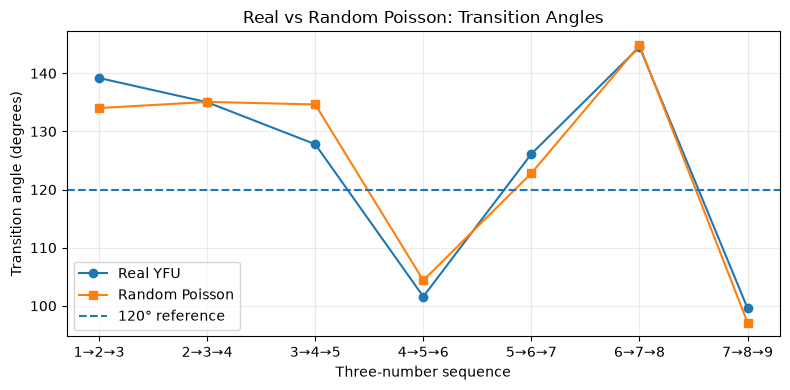

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_geometry(Lambda):
    # Center the nine number representations
    C = Lambda - Lambda.mean(axis=0, keepdims=True)

    # Singular values
    s = np.linalg.svd(C, compute_uv=False)

    # Affine rank
    rank = np.linalg.matrix_rank(C)

    # Variance contribution of each dimension
    eigenvalues = s**2
    p = eigenvalues / eigenvalues.sum()
    p = p[p > 1e-12]

    # Effective rank
    effective_rank = np.exp(-np.sum(p * np.log(p)))

    # Consecutive number transitions
    transitions = np.diff(Lambda, axis=0)

    # Angles between consecutive transitions
    angles = []

    for i in range(len(transitions) - 1):
        a = transitions[i]
        b = transitions[i + 1]

        cosine = np.dot(a, b) / (
            np.linalg.norm(a) * np.linalg.norm(b)
        )

        angle = np.degrees(
            np.arccos(np.clip(cosine, -1, 1))
        )
        angles.append(angle)

    return {
        "affine_rank": rank,
        "effective_rank": effective_rank,
        "mean_angle": np.mean(angles),
        "angles": np.array(angles),
    }


# Compute geometry for real and simulated data
real_geom = compute_geometry(Lambda_corrected)
null_geom = compute_geometry(Lambda_null)

comparison = pd.DataFrame({
    "Metric": [
        "Affine rank",
        "Effective rank",
        "Mean transition angle (degrees)",
    ],
    "Real YFU": [
        real_geom["affine_rank"],
        real_geom["effective_rank"],
        real_geom["mean_angle"],
    ],
    "Random Poisson": [
        null_geom["affine_rank"],
        null_geom["effective_rank"],
        null_geom["mean_angle"],
    ],
})

display(comparison.round(4))

# Compare individual transition angles
plt.figure(figsize=(8, 4))

labels = [
    "1→2→3", "2→3→4", "3→4→5",
    "4→5→6", "5→6→7", "6→7→8",
    "7→8→9",
]

plt.plot(
    labels,
    real_geom["angles"],
    marker="o",
    label="Real YFU",
)

plt.plot(
    labels,
    null_geom["angles"],
    marker="s",
    label="Random Poisson",
)

plt.axhline(
    120,
    linestyle="--",
    label="120° reference",
)

plt.ylabel("Transition angle (degrees)")
plt.xlabel("Three-number sequence")
plt.title("Real vs Random Poisson: Transition Angles")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Class sizes: [53 67 52 62 51 48 65 49 47]

GEOMETRY COMPARISON
------------------------------------------------------------
Real YFU           | Rank: 8 | Effective rank: 5.6859 | Mean angle: 124.8348
Random Poisson     | Rank: 8 | Effective rank: 5.7382 | Mean angle: 124.6934
Expected null      | Rank: 1 | Effective rank: 1.0000 | Mean angle: 128.5714


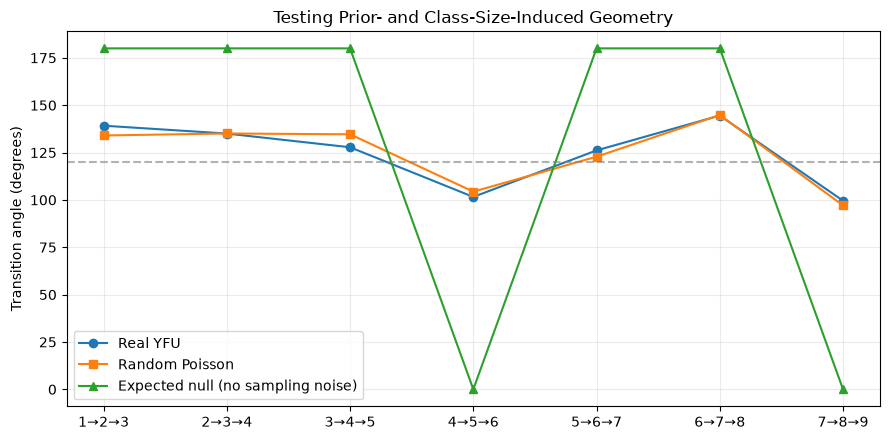

In [24]:

# STEP 20 — Expected geometry under the Poisson null

# Pooled feature-wise mean spike counts
mu = X_original.mean(axis=0)

# Actual number presentation counts
n_class = np.array([
    np.sum(y == k) for k in range(1, 10)
])

# Expected Bayesian posterior means under H0
Lambda_expected = np.vstack([
    (alpha + n_k * mu) / (beta + n_k)
    for n_k in n_class
])

# Compute geometry
expected_geom = compute_geometry(Lambda_expected)

print("Class sizes:", n_class)

print("\nGEOMETRY COMPARISON")
print("-" * 60)

for name, g in [
    ("Real YFU", real_geom),
    ("Random Poisson", null_geom),
    ("Expected null", expected_geom)
]:
    print(
        f"{name:18s} | "
        f"Rank: {g['affine_rank']} | "
        f"Effective rank: {g['effective_rank']:.4f} | "
        f"Mean angle: {g['mean_angle']:.4f}"
    )

# Plot all three angle sequences
labels = [
    "1→2→3", "2→3→4", "3→4→5",
    "4→5→6", "5→6→7", "6→7→8",
    "7→8→9"
]

plt.figure(figsize=(9, 4.5))

plt.plot(
    labels, real_geom["angles"],
    "o-", label="Real YFU"
)

plt.plot(
    labels, null_geom["angles"],
    "s-", label="Random Poisson"
)

plt.plot(
    labels, expected_geom["angles"],
    "^-", label="Expected null (no sampling noise)"
)

plt.axhline(120, linestyle="--",
            color="gray", alpha=0.6)

plt.ylabel("Transition angle (degrees)")
plt.title("Testing Prior- and Class-Size-Induced Geometry")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


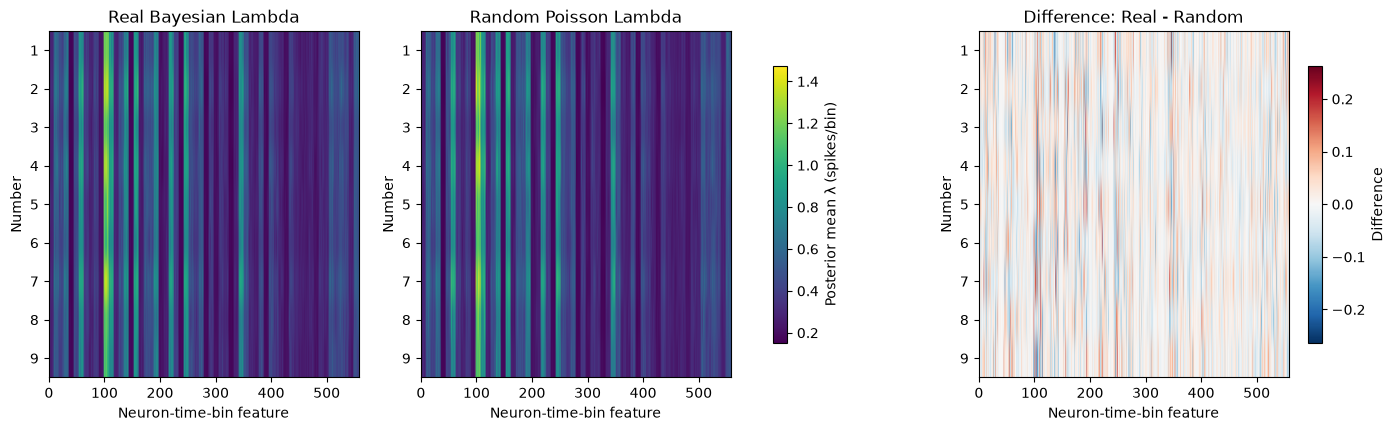

In [25]:

import numpy as np
import matplotlib.pyplot as plt

real = Lambda_corrected
sim = Lambda_null

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

vmin = min(real.min(), sim.min())
vmax = max(real.max(), sim.max())

im = axes[0].imshow(
    real, aspect="auto", cmap="viridis",
    vmin=vmin, vmax=vmax
)
axes[0].set_title("Real Bayesian Lambda")

axes[1].imshow(
    sim, aspect="auto", cmap="viridis",
    vmin=vmin, vmax=vmax
)
axes[1].set_title("Random Poisson Lambda")

diff = real - sim
limit = np.max(np.abs(diff))

im_diff = axes[2].imshow(
    diff, aspect="auto", cmap="RdBu_r",
    vmin=-limit, vmax=limit
)
axes[2].set_title("Difference: Real - Random")

for ax in axes:
    ax.set_xlabel("Neuron-time-bin feature")
    ax.set_ylabel("Number")
    ax.set_yticks(range(9))
    ax.set_yticklabels(range(1, 10))

fig.colorbar(im, ax=axes[:2], shrink=0.8,
             label="Posterior mean λ (spikes/bin)")
fig.colorbar(im_diff, ax=axes[2], shrink=0.8,
             label="Difference")

plt.show()


In [26]:

from scipy.stats import pearsonr

real_flat = Lambda_corrected.ravel()
sim_flat = Lambda_null.ravel()

print("MATRIX SIMILARITY")
print("-" * 45)

print("Mean Real:", real_flat.mean())
print("Mean Null:", sim_flat.mean())

print("Standard deviation Real:", real_flat.std())
print("Standard deviation Null:", sim_flat.std())

print("Mean absolute difference:",
      np.mean(np.abs(real_flat - sim_flat)))

print("RMSE:",
      np.sqrt(np.mean((real_flat - sim_flat)**2)))

print("Pearson correlation:",
      pearsonr(real_flat, sim_flat).statistic)

print("\nCORRELATION FOR EACH NUMBER")
for k in range(9):
    r = pearsonr(
        Lambda_corrected[k],
        Lambda_null[k]
    ).statistic

    print(f"Number {k+1}: {r:.4f}")


MATRIX SIMILARITY
---------------------------------------------
Mean Real: 0.4164958989897748
Mean Null: 0.4164317178662798
Standard deviation Real: 0.2222055550408052
Standard deviation Null: 0.2232747279086504
Mean absolute difference: 0.036308206310458044
RMSE: 0.05027662798543348
Pearson correlation: 0.9745369365254796

CORRELATION FOR EACH NUMBER
Number 1: 0.9717
Number 2: 0.9798
Number 3: 0.9721
Number 4: 0.9805
Number 5: 0.9717
Number 6: 0.9690
Number 7: 0.9784
Number 8: 0.9741
Number 9: 0.9663


RAW MATRIX CORRELATION: 0.9745369365254796
CENTERED MATRIX CORRELATION: 0.3608314163409605

CENTERED MATRIX MAGNITUDES
Real Frobenius norm: 3.0045699079469173
Null Frobenius norm: 3.1201181655177215

CENTERED MATRIX DIFFERENCE
RMSE: 0.04887680654274075


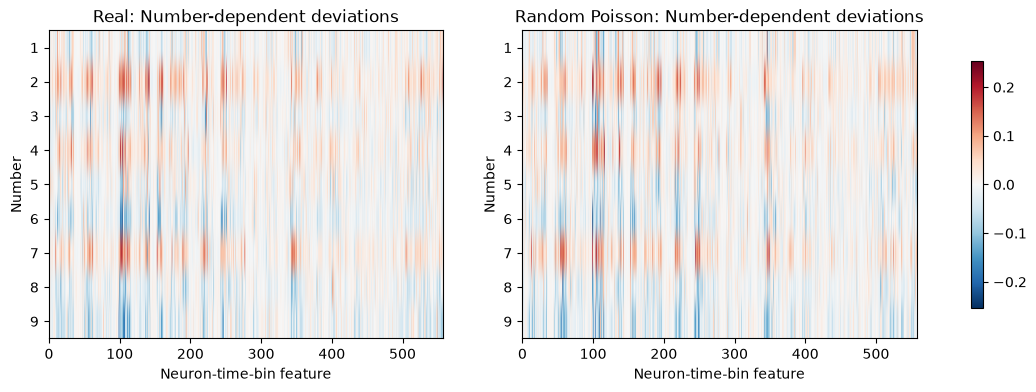

In [27]:
# STEP 23 — Compare number-dependent representations

from scipy.stats import pearsonr
import numpy as np
import matplotlib.pyplot as plt

C_real = Lambda_corrected - Lambda_corrected.mean(
    axis=0, keepdims=True
)

C_null = Lambda_null - Lambda_null.mean(
    axis=0, keepdims=True
)

# Entrywise correlation after centering
r_centered = pearsonr(
    C_real.ravel(),
    C_null.ravel()
).statistic

print("RAW MATRIX CORRELATION:",
      pearsonr(
          Lambda_corrected.ravel(),
          Lambda_null.ravel()
      ).statistic)

print("CENTERED MATRIX CORRELATION:", r_centered)

print("\nCENTERED MATRIX MAGNITUDES")
print("Real Frobenius norm:", np.linalg.norm(C_real))
print("Null Frobenius norm:", np.linalg.norm(C_null))

print("\nCENTERED MATRIX DIFFERENCE")
print("RMSE:", np.sqrt(np.mean((C_real - C_null)**2)))

# Heatmaps with the same color scale
limit = max(
    np.abs(C_real).max(),
    np.abs(C_null).max()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, matrix, title in zip(
    axes,
    [C_real, C_null],
    ["Real: Number-dependent deviations",
     "Random Poisson: Number-dependent deviations"]
):
    im = ax.imshow(
        matrix,
        aspect="auto",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(title)
    ax.set_xlabel("Neuron-time-bin feature")
    ax.set_ylabel("Number")
    ax.set_yticks(range(9))
    ax.set_yticklabels(range(1, 10))

fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In [28]:
# Residuals relative to the expected Poisson-null matrix
R_real = Lambda_corrected - Lambda_expected
R_null = Lambda_null - Lambda_expected

# Center residuals across numbers
R_real -= R_real.mean(axis=0, keepdims=True)
R_null -= R_null.mean(axis=0, keepdims=True)

print("RESIDUAL MATRIX COMPARISON")
print("-" * 45)

print("Residual correlation:",
      np.corrcoef(R_real.ravel(), R_null.ravel())[0, 1])

print("Real residual norm:",
      np.linalg.norm(R_real))

print("Null residual norm:",
      np.linalg.norm(R_null))

print("Residual RMSE:",
      np.sqrt(np.mean((R_real - R_null)**2)))

RESIDUAL MATRIX COMPARISON
---------------------------------------------
Residual correlation: -0.031018450736476015
Real residual norm: 2.368614133877063
Null residual norm: 2.454835580099696
Residual RMSE: 0.04887680654274075


In [29]:

import numpy as np

# Reproducible random generator
rng = np.random.default_rng(2026)

# Preserve experimental dimensions only
N = 494
N_NEURONS = 62
N_BINS = 9
P = N_NEURONS * N_BINS

# Independent synthetic ground-truth Poisson rates
# Gamma(shape=2, scale=0.5) has mean 1 count/bin
lambda_true = rng.gamma(
    shape=2.0,
    scale=0.5,
    size=(N_NEURONS, N_BINS)
)

# Generate new Poisson spike counts
X_synthetic = rng.poisson(
    lam=lambda_true.reshape(1, P),
    size=(N, P)
)

print("TRUE SYNTHETIC RATES")
print("Shape:", lambda_true.shape)
print("Mean:", lambda_true.mean())
print("Minimum:", lambda_true.min())
print("Maximum:", lambda_true.max())

print("\nSYNTHETIC SPIKE COUNTS")
print("Shape:", X_synthetic.shape)
print("Mean count:", X_synthetic.mean())
print("Total spikes:", X_synthetic.sum())

print("\nNUMBER LABELS")
print("Shape:", y.shape)
print("Class counts:", np.bincount(y)[1:])

print("\nGround-truth number selectivity: NONE")


TRUE SYNTHETIC RATES
Shape: (62, 9)
Mean: 1.0128835502155316
Minimum: 0.03028361036344829
Maximum: 4.578068452111285

SYNTHETIC SPIKE COUNTS
Shape: (494, 558)
Mean count: 1.0072410140321855
Total spikes: 277648

NUMBER LABELS
Shape: (494,)
Class counts: [53 67 52 62 51 48 65 49 47]

Ground-truth number selectivity: NONE


In [30]:
from pathlib import Path

paths = [
    ROOT / "src" / "gamma_poisson_naive_bayes.py",
    ROOT / "src" / "gamma_poisson_decoding.py",
]

keywords = [
    "GridSearchCV",
    "ParameterGrid",
    "StratifiedGroupKFold",
    "param_grid",
    "m_grid",
    "tau_grid",
    "best_params",
    "inner_cv",
    "outer_cv",
    "geomspace",
]

for path in paths:
    print(f"\n{'=' * 65}")
    print(path.name)
    print("=" * 65)

    lines_source = path.read_text(
        encoding="utf-8"
    ).splitlines()

    for i, line in enumerate(lines_source):
        if any(k.lower() in line.lower() for k in keywords):
            print(f"{i+1:4d}: {line.strip()[:140]}")


gamma_poisson_naive_bayes.py

gamma_poisson_decoding.py
   7: 2. Run 5-fold StratifiedGroupKFold cross-validation.
  62: from sklearn.model_selection import StratifiedGroupKFold
 297: cv = StratifiedGroupKFold(


In [31]:
from pathlib import Path
import json

keywords = [
    "prior_strength",
    "prior_mean",
    "tau_grid",
    "m_grid",
    "best_tau",
    "best_m",
    "geomspace",
    "lambda_metadata.csv",
]

matches = []

for path in ROOT.rglob("*"):
    if not path.is_file() or path.suffix not in {".py", ".ipynb"}:
        continue

    if any(part.startswith((".git", ".venv")) for part in path.parts):
        continue

    try:
        if path.suffix == ".ipynb":
            nb = json.loads(path.read_text(encoding="utf-8"))
            source = "\n".join(
                "".join(cell.get("source", []))
                for cell in nb.get("cells", [])
                if cell.get("cell_type") == "code"
            )
        else:
            source = path.read_text(encoding="utf-8")

        found = [k for k in keywords if k.lower() in source.lower()]

        if found:
            matches.append((path.relative_to(ROOT), found))

    except (UnicodeError, OSError, ValueError):
        continue

print(f"Found {len(matches)} matching files:\n")

for path, found in matches:
    print(f"{path}")
    print(f"  Matches: {', '.join(found)}")
    

Found 5 matching files:

notebooks\statisticaltestfig1.ipynb
  Matches: prior_mean, best_m
notebooks1\08_gamma_poisson_bayesian_decoding.ipynb
  Matches: prior_strength, prior_mean, tau_grid, best_tau, best_m, geomspace
notebooks1\gamma_poisson_naive_bayes.ipynb
  Matches: prior_strength, prior_mean, geomspace
notebooks1\gammA_poisson_naive_updated.ipynb
  Matches: prior_strength, prior_mean, geomspace, lambda_metadata.csv
notebooks1\YFU_Bayesian_Validation.ipynb
  Matches: prior_strength, prior_mean, tau_grid, m_grid, best_tau, best_m, geomspace, lambda_metadata.csv


In [32]:
import json

path = ROOT / "notebooks1" / "gammA_poisson_naive_updated.ipynb"
nb = json.loads(path.read_text(encoding="utf-8"))

keywords = [
    "geomspace",
    "prior_strength",
    "prior_mean",
    "lambda_metadata.csv",
    "StratifiedGroupKFold",
    "def ",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    found = [k for k in keywords if k.lower() in source.lower()]

    if found:
        print(f"\n{'=' * 60}")
        print(f"CELL {i + 1} | {', '.join(found)}")
        print("=" * 60)

        for line in source.splitlines():
            if any(k.lower() in line.lower() for k in keywords):
                print(line[:180])


CELL 5 | StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold
outer_cv = StratifiedGroupKFold(

CELL 7 | def 
def gamma_sufficient_stats(X_train, y_train, classes):

CELL 9 | def 
def predict_gamma_poisson_from_stats(

CELL 11 | geomspace, prior_strength, prior_mean
prior_means_nested = np.geomspace(
prior_strengths_nested = np.geomspace(
print(prior_means_nested)
print(prior_strengths_nested)
    len(prior_means_nested)
    * len(prior_strengths_nested)

CELL 12 | StratifiedGroupKFold
from sklearn.model_selection import StratifiedGroupKFold
inner_cv = StratifiedGroupKFold(

CELL 14 | prior_strength, prior_mean
for m in prior_means_nested:
    for s in prior_strengths_nested:
            "prior_mean": m,
            "prior_strength": s,

CELL 16 | prior_strength, prior_mean
print("m     =", best["prior_mean"])
print("tau   =", best["prior_strength"])

CELL 19 | prior_strength, prior_mean, StratifiedGroupKFold, def 
def run_nested_gamma_subject(
    prior_means

In [33]:
for cell_number in [29, 30]:
    cell = nb["cells"][cell_number - 1]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 70}")
    print(f"CELL {cell_number}")
    print("=" * 70)
    print(source)


CELL 29
def select_full_data_prior(
    X,
    y,
    groups,
    classes,
    prior_means,
    prior_strengths,
):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    splits = list(
        cv.split(X, y, groups=groups)
    )

    fold_data = []

    for train_idx, val_idx in splits:

        X_train = X[train_idx]
        y_train = y[train_idx]

        X_val = X[val_idx]
        y_val = y[val_idx]

        sum_counts, n_class = gamma_sufficient_stats(
            X_train,
            y_train,
            classes
        )

        fold_data.append(
            (
                X_val,
                y_val,
                sum_counts,
                n_class
            )
        )

    results = []

    for m in prior_means:

        for s in prior_strengths:

            alpha = m * s
            beta = s

            all_true = []
            all_pred = []

            for (
                X_val,
                y_val,
  

In [34]:
# Print the complete final portion of the prior-selection function
source_29 = "".join(nb["cells"][28]["source"])
print(source_29[-3500:])

print("\n" + "=" * 65)
print("POSTERIOR MATRIX FUNCTION")
print("=" * 65)

source_30 = "".join(nb["cells"][29]["source"])
print(source_30)

def select_full_data_prior(
    X,
    y,
    groups,
    classes,
    prior_means,
    prior_strengths,
):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    splits = list(
        cv.split(X, y, groups=groups)
    )

    fold_data = []

    for train_idx, val_idx in splits:

        X_train = X[train_idx]
        y_train = y[train_idx]

        X_val = X[val_idx]
        y_val = y[val_idx]

        sum_counts, n_class = gamma_sufficient_stats(
            X_train,
            y_train,
            classes
        )

        fold_data.append(
            (
                X_val,
                y_val,
                sum_counts,
                n_class
            )
        )

    results = []

    for m in prior_means:

        for s in prior_strengths:

            alpha = m * s
            beta = s

            all_true = []
            all_pred = []

            for (
                X_val,
                y_val,
           

In [35]:
source = "".join(nb["cells"][28]["source"])
lines = source.splitlines()

for i, line in enumerate(lines):
    if "results_df = pd.DataFrame(results)" in line:
        print("\n".join(lines[i:]))
        break

    results_df = pd.DataFrame(results)

    best = (
        results_df
        .sort_values(
            [
                "balanced_accuracy",
                "accuracy"
            ],
            ascending=False
        )
        .iloc[0]
    )

    return best, results_df


In [36]:
# Load original function definitions from the source notebook.
# These are trusted local notebook cells, not new implementations.

for cell_number in [7, 9, 11, 29, 30]:
    source = "".join(nb["cells"][cell_number - 1]["source"])

    if cell_number == 11:
        # Execute only the prior grid definitions
        import ast
        tree = ast.parse(source)
        selected = []

        for node in tree.body:
            if isinstance(node, ast.Assign):
                targets = [
                    t.id for t in node.targets
                    if isinstance(t, ast.Name)
                ]
                if any(
                    t in ("prior_means_nested", "prior_strengths_nested")
                    for t in targets
                ):
                    selected.append(node)

        exec(compile(ast.Module(body=selected, type_ignores=[]),
                     "<prior_grids>", "exec"))
    else:
        exec(source)

print("Prior mean grid:", prior_means_nested)
print("Prior strength grid:", prior_strengths_nested)

Prior mean grid: [0.03       0.04000502 0.05334671 0.07113787 0.09486238 0.12649904
 0.16868653 0.22494358 0.29996239 0.4       ]
Prior strength grid: [ 10.          13.39940319  17.95440059  24.05782525  32.23605005
  43.19438319  57.87789559  77.55292588 103.91629226 139.24162981
 186.57547387 250.        ]


In [37]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold

classes = np.arange(1, 10)

best_sim, results_sim = select_full_data_prior(
    X=X_synthetic,
    y=y,
    groups=groups,
    classes=classes,
    prior_means=prior_means_nested,
    prior_strengths=prior_strengths_nested,
)

print("SYNTHETIC BAYESIAN PRIOR")
print("=" * 45)

print(f"Optimal prior mean (m): {best_sim['prior_mean']:.6f}")
print(f"Optimal prior strength (tau): {best_sim['prior_strength']:.6f}")
print(f"Alpha: {best_sim['alpha']:.6f}")
print(f"Beta: {best_sim['beta']:.6f}")

print(f"\nCV accuracy: {best_sim['accuracy']:.4%}")
print(f"CV balanced accuracy: {best_sim['balanced_accuracy']:.4%}")
print(f"Chance accuracy: {1/9:.4%}")

print("\nTop 5 parameter combinations:")
display(
    results_sim.sort_values(
        ["balanced_accuracy", "accuracy"],
        ascending=False
    ).head(5)
)


SYNTHETIC BAYESIAN PRIOR
Optimal prior mean (m): 0.168687
Optimal prior strength (tau): 32.236050
Alpha: 5.437788
Beta: 32.236050

CV accuracy: 16.8016%
CV balanced accuracy: 14.1513%
Chance accuracy: 11.1111%

Top 5 parameter combinations:


,prior_mean,prior_strength,alpha,beta,accuracy,balanced_accuracy
76,0.168687,32.236050,5.437788,32.236050,0.168016,0.141513
64,0.126499,32.236050,4.077829,32.236050,0.168016,0.141411
40,0.071138,32.236050,2.293204,32.236050,0.168016,0.141092
52,0.094862,32.236050,3.057989,32.236050,0.165992,0.139434
15,0.040005,24.057825,0.962434,24.057825,0.163968,0.138094


In [38]:

# Synthetic prior selected through cross-validation
alpha_sim = float(best_sim["alpha"])
beta_sim = float(best_sim["beta"])

# Compute sufficient statistics using synthetic data
sum_counts_sim, n_class_sim = gamma_sufficient_stats(
    X_synthetic,
    y,
    classes
)

# Construct the Bayesian posterior-mean matrix
Lambda_synthetic = (
    alpha_sim + sum_counts_sim
) / (
    beta_sim + n_class_sim[:, None]
)

print("SYNTHETIC POSTERIOR MATRIX")
print("=" * 45)

print("Shape:", Lambda_synthetic.shape)
print("Minimum:", Lambda_synthetic.min())
print("Maximum:", Lambda_synthetic.max())
print("Mean:", Lambda_synthetic.mean())
print("Standard deviation:", Lambda_synthetic.std())

print("\nPrior parameters:")
print("Alpha:", alpha_sim)
print("Beta:", beta_sim)

print("\nContains NaN:", np.isnan(Lambda_synthetic).any())


SYNTHETIC POSTERIOR MATRIX
Shape: (9, 558)
Minimum: 0.05592357483913478
Maximum: 3.29958505372116
Mean: 0.6948277141382238
Standard deviation: 0.4532514219862689

Prior parameters:
Alpha: 5.437787521804211
Beta: 32.23605004590836

Contains NaN: False


In [39]:

# Geometry of the real Bayesian representation
geom_real = compute_geometry(Lambda_corrected)

# Geometry of independently simulated Poisson neurons
geom_sim = compute_geometry(Lambda_synthetic)

print("REAL YFU vs INDEPENDENT POISSON SIMULATION")
print("=" * 55)

for key in ["affine_rank", "effective_rank", "mean_angle"]:
    print(
        f"{key:20s} | "
        f"Real: {geom_real[key]:10.4f} | "
        f"Synthetic: {geom_sim[key]:10.4f}"
    )

print("\nIndividual transition angles:")
print("Real:", np.round(geom_real["angles"], 2))
print("Synthetic:", np.round(geom_sim["angles"], 2))


REAL YFU vs INDEPENDENT POISSON SIMULATION
affine_rank          | Real:     8.0000 | Synthetic:     8.0000
effective_rank       | Real:     5.6859 | Synthetic:     7.4851
mean_angle           | Real:   124.8348 | Synthetic:   122.6339

Individual transition angles:
Real: [139.19 135.03 127.8  101.59 126.14 144.53  99.57]
Synthetic: [125.29 128.38 128.55 112.43 122.64 128.69 112.46]


In [41]:

import numpy as np
import pandas as pd

# ============================================
# STEP 35 — INDEPENDENT POISSON NULL SIMULATIONS
# ============================================

N_SIM = 100
rng_null = np.random.default_rng(2027)

null_results = []

for b in range(N_SIM):

    # 1. Generate independent true Poisson rates
    lambda_true_b = rng_null.gamma(
        shape=2.0,
        scale=0.5,
        size=(62, 9)
    )

    # 2. Generate new synthetic spike counts
    X_b = rng_null.poisson(
        lam=lambda_true_b.reshape(1, 558),
        size=(len(y), 558)
    )

    # 3. Independently optimize Bayesian prior
    best_b, _ = select_full_data_prior(
        X=X_b,
        y=y,
        groups=groups,
        classes=classes,
        prior_means=prior_means_nested,
        prior_strengths=prior_strengths_nested,
    )

    # 4. Construct posterior-mean matrix
    S_b, n_b = gamma_sufficient_stats(
        X_b, y, classes
    )

    Lambda_b = (
        float(best_b["alpha"]) + S_b
    ) / (
        float(best_b["beta"]) + n_b[:, None]
    )

    # 5. Calculate geometry
    geom_b = compute_geometry(Lambda_b)

    # 6. Store results
    null_results.append({
        "simulation": b + 1,
        "prior_mean": float(best_b["prior_mean"]),
        "prior_strength": float(best_b["prior_strength"]),
        "cv_accuracy": float(best_b["accuracy"]),
        "cv_balanced_accuracy": float(
            best_b["balanced_accuracy"]
        ),
        "affine_rank": int(geom_b["affine_rank"]),
        "effective_rank": float(geom_b["effective_rank"]),
        "mean_angle": float(geom_b["mean_angle"]),
    })

    # 7. Print progress every 10 simulations
    if (b + 1) % 10 == 0:
        print(f"Completed {b + 1}/{N_SIM} simulations")

# ============================================
# SUMMARY
# ============================================

null_df = pd.DataFrame(null_results)

print("\n" + "=" * 55)
print("INDEPENDENT POISSON NULL SIMULATION SUMMARY")
print("=" * 55)

print("Completed simulations:", len(null_df))

display(null_df.describe().round(4))


Completed 10/100 simulations
Completed 20/100 simulations
Completed 30/100 simulations
Completed 40/100 simulations
Completed 50/100 simulations
Completed 60/100 simulations
Completed 70/100 simulations
Completed 80/100 simulations
Completed 90/100 simulations
Completed 100/100 simulations

INDEPENDENT POISSON NULL SIMULATION SUMMARY
Completed simulations: 100


,simulation,prior_mean,prior_strength,cv_accuracy,cv_balanced_accuracy,affine_rank,effective_rank,mean_angle
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.0,100.0000,100.0000
mean,50.5000,0.1906,54.7554,0.1487,0.1267,8.0,7.1757,121.8601
std,29.0115,0.1420,69.9434,0.0125,0.0116,0.0,1.0376,2.2022
min,1.0000,0.0300,10.0000,0.1235,0.1018,8.0,4.4490,118.3103
25%,25.7500,0.0533,13.3994,0.1392,0.1182,8.0,6.7243,120.2954
50%,50.5000,0.1476,17.9544,0.1478,0.1259,8.0,7.8011,121.2896
75%,75.2500,0.3000,57.8779,0.1559,0.1320,8.0,7.8614,123.2971
max,100.0000,0.4000,250.0000,0.1842,0.1585,8.0,7.9154,127.8319


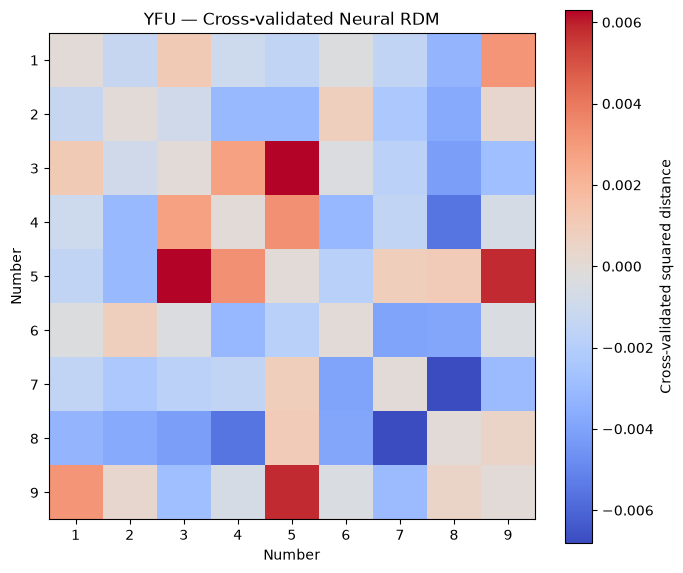

RDM shape: (9, 9)

RDM:
[[ 0.     -0.0013  0.0011 -0.001  -0.0015 -0.0003 -0.0015 -0.0033  0.0032]
 [-0.0013  0.     -0.0009 -0.0031 -0.0031  0.0008 -0.0023 -0.0037  0.0003]
 [ 0.0011 -0.0009  0.      0.0027  0.0063 -0.0004 -0.0018 -0.0042 -0.0028]
 [-0.001  -0.0031  0.0027  0.      0.0033 -0.0031 -0.0015 -0.0055 -0.0007]
 [-0.0015 -0.0031  0.0063  0.0033  0.     -0.0018  0.0009  0.001   0.0058]
 [-0.0003  0.0008 -0.0004 -0.0031 -0.0018  0.     -0.0039 -0.0039 -0.0004]
 [-0.0015 -0.0023 -0.0018 -0.0015  0.0009 -0.0039  0.     -0.0068 -0.003 ]
 [-0.0033 -0.0037 -0.0042 -0.0055  0.001  -0.0039 -0.0068  0.      0.0005]
 [ 0.0032  0.0003 -0.0028 -0.0007  0.0058 -0.0004 -0.003   0.0005  0.    ]]

Mean distance: -0.0009960123179051387
Minimum: -0.006803396416713202
Maximum: 0.006308850973073848
Positive pairs: 11 /36


In [42]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

# Original neural population data
X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
trial_groups = np.asarray(groups)
numbers = np.arange(1, 10)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Estimate each number's population response
# independently in five non-overlapping trial partitions
fold_means = []

for _, test_idx in cv.split(X, labels, trial_groups):

    X_fold = X[test_idx]
    y_fold = labels[test_idx]

    means = np.vstack([
        X_fold[y_fold == k].mean(axis=0)
        for k in numbers
    ])

    fold_means.append(means)

fold_means = np.stack(fold_means)

# Cross-validated squared Euclidean distances
D_cv = np.zeros((9, 9))

for i in range(9):
    for j in range(i + 1, 9):

        delta = (
            fold_means[:, i, :]
            - fold_means[:, j, :]
        )

        cross = delta @ delta.T

        # Exclude within-fold products
        value = (
            cross.sum() - np.trace(cross)
        ) / (5 * 4 * X.shape[1])

        D_cv[i, j] = value
        D_cv[j, i] = value

# Display the geometry
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(D_cv, cmap="coolwarm")

ax.set_xticks(range(9), numbers)
ax.set_yticks(range(9), numbers)

ax.set_xlabel("Number")
ax.set_ylabel("Number")
ax.set_title("YFU — Cross-validated Neural RDM")

fig.colorbar(
    im,
    ax=ax,
    label="Cross-validated squared distance"
)

plt.tight_layout()
plt.show()

print("RDM shape:", D_cv.shape)
print("\nRDM:")
print(np.round(D_cv, 4))

upper = D_cv[np.triu_indices(9, 1)]

print("\nMean distance:", upper.mean())
print("Minimum:", upper.min())
print("Maximum:", upper.max())
print("Positive pairs:", np.sum(upper > 0), "/36")


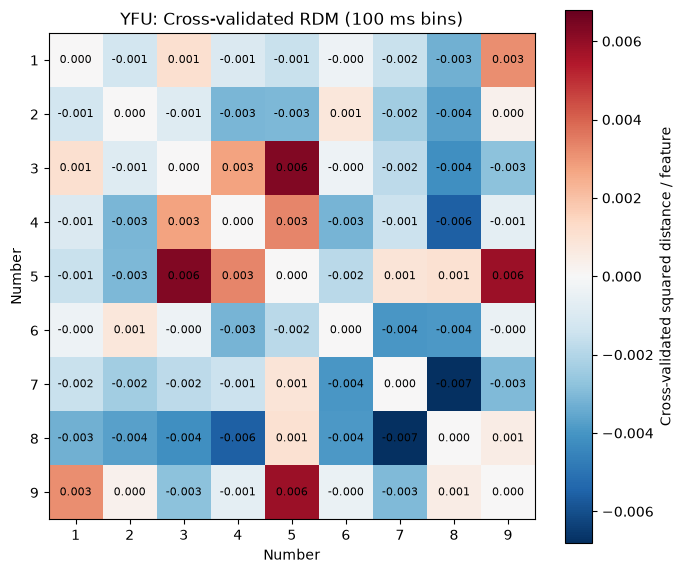

Positive pairs: 11 / 36


In [43]:

import numpy as np
import matplotlib.pyplot as plt

# Existing cross-validated RDM
D = np.asarray(D_cv)

fig, ax = plt.subplots(figsize=(7, 6))

limit = np.max(np.abs(D))
im = ax.imshow(
    D,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

ax.set_xticks(range(9))
ax.set_yticks(range(9))
ax.set_xticklabels(range(1, 10))
ax.set_yticklabels(range(1, 10))

ax.set_xlabel("Number")
ax.set_ylabel("Number")
ax.set_title("YFU: Cross-validated RDM (100 ms bins)")

for i in range(9):
    for j in range(9):
        ax.text(
            j, i, f"{D[i,j]:.3f}",
            ha="center", va="center", fontsize=8
        )

plt.colorbar(im, ax=ax, label="Cross-validated squared distance / feature")
plt.tight_layout()
plt.show()

print("Positive pairs:", np.sum(D[np.triu_indices(9, 1)] > 0), "/ 36")


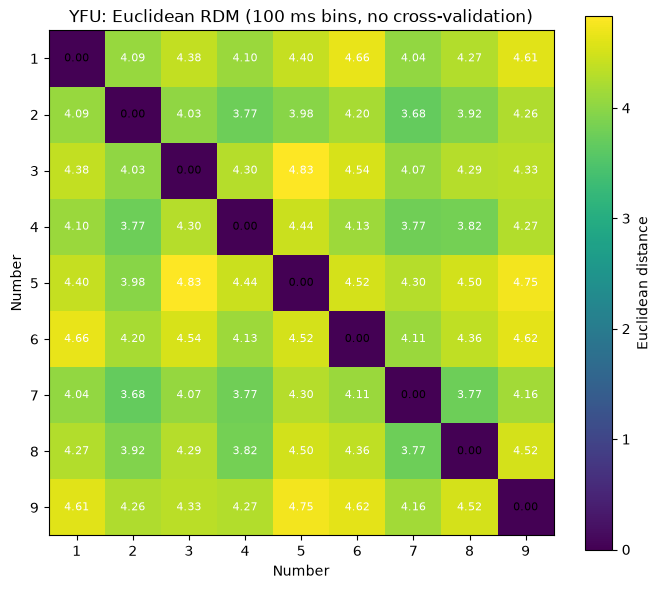

Centroid matrix: (9, 558)
RDM shape: (9, 9)
Distance between 1 and 2: 4.089951297268957


In [44]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# Original experimental spike counts
X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
numbers = np.arange(1, 10)

# One average population vector per number
centroids = np.vstack([
    X[labels == k].mean(axis=0)
    for k in numbers
])

# Ordinary Euclidean distances between centroids
D_euclidean = cdist(centroids, centroids, metric="euclidean")

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(D_euclidean, cmap="viridis")

ax.set_xticks(range(9))
ax.set_yticks(range(9))
ax.set_xticklabels(numbers)
ax.set_yticklabels(numbers)

ax.set_xlabel("Number")
ax.set_ylabel("Number")
ax.set_title("YFU: Euclidean RDM (100 ms bins, no cross-validation)")

for i in range(9):
    for j in range(9):
        ax.text(
            j, i, f"{D_euclidean[i,j]:.2f}",
            ha="center", va="center",
            fontsize=8,
            color="white" if D_euclidean[i,j] > D_euclidean.max()/2 else "black"
        )

plt.colorbar(im, ax=ax, label="Euclidean distance")
plt.tight_layout()
plt.show()

print("Centroid matrix:", centroids.shape)
print("RDM shape:", D_euclidean.shape)
print("Distance between 1 and 2:", D_euclidean[0, 1])


In [45]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

X = np.asarray(X_original)
labels = np.asarray(y)
trial_groups = np.asarray(groups)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []

for fold, (_, test_idx) in enumerate(
    cv.split(X, labels, trial_groups), start=1
):
    counts = {
        f"Number {k}": int(np.sum(labels[test_idx] == k))
        for k in range(1, 10)
    }

    rows.append({
        "Fold": fold,
        "Presentations": len(test_idx),
        "Unique trials": len(np.unique(trial_groups[test_idx])),
        **counts
    })

fold_distribution = pd.DataFrame(rows)

display(fold_distribution)

print("\nTotal presentations:", fold_distribution["Presentations"].sum())
print("Total per number:")
print(fold_distribution.iloc[:, 3:].sum())


,Fold,Presentations,Unique trials,Number 1,Number 2,Number 3,Number 4,Number 5,Number 6,Number 7,Number 8,Number 9
0,1,99,58,11,14,10,13,10,9,13,10,9
1,2,99,59,10,14,11,13,10,9,13,10,9
2,3,99,59,11,13,10,12,10,10,13,10,10
3,4,99,58,11,13,11,12,10,10,13,9,10
4,5,98,57,10,13,10,12,11,10,13,10,9



Total presentations: 494
Total per number:
Number 1    53
Number 2    67
Number 3    52
Number 4    62
Number 5    51
Number 6    48
Number 7    65
Number 8    49
Number 9    47
dtype: int64


In [46]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist

X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
numbers = np.arange(1, 10)

# Mean population vector for each number
centroids = np.vstack([
    X[labels == k].mean(axis=0)
    for k in numbers
])

# Between-number separation
between_distances = pdist(centroids, metric="euclidean")

# Within-number variability:
# RMS distance of individual trials from their centroid
rows = []

for k in numbers:
    X_k = X[labels == k]
    mu_k = X_k.mean(axis=0)

    squared_deviations = np.sum((X_k - mu_k)**2, axis=1)
    rms_distance = np.sqrt(np.mean(squared_deviations))

    rows.append({
        "Number": k,
        "Presentations": len(X_k),
        "Within-number RMS": rms_distance
    })

noise_df = pd.DataFrame(rows)

print("WITHIN-NUMBER VARIABILITY")
display(noise_df)

print("\nBETWEEN-NUMBER SEPARATION")
print("Mean centroid distance:", between_distances.mean())
print("Minimum centroid distance:", between_distances.min())
print("Maximum centroid distance:", between_distances.max())

print("\nSIGNAL-TO-NOISE SUMMARY")
print("Mean within-number RMS:", noise_df["Within-number RMS"].mean())
print(
    "Between / Within ratio:",
    between_distances.mean() / noise_df["Within-number RMS"].mean()
)


WITHIN-NUMBER VARIABILITY


,Number,Presentations,Within-number RMS
0,1,53,22.187813
1,2,67,22.247900
2,3,52,22.183174
3,4,62,22.190172
4,5,51,22.337611
5,6,48,22.162545
6,7,65,22.290965
7,8,49,22.054871
8,9,47,22.324533



BETWEEN-NUMBER SEPARATION
Mean centroid distance: 4.244624851642737
Minimum centroid distance: 3.6827561581824075
Maximum centroid distance: 4.829343846409707

SIGNAL-TO-NOISE SUMMARY
Mean within-number RMS: 22.2199536223679
Between / Within ratio: 0.19102761975928925


In [47]:

import numpy as np
import pandas as pd

X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
numbers = np.arange(1, 10)

centroids = []
noise_terms = []
counts = []

for k in numbers:
    X_k = X[labels == k]
    n = len(X_k)
    mu = X_k.mean(axis=0)

    # Sum of per-feature sample variances / n
    noise = np.var(X_k, axis=0, ddof=1).sum() / n

    centroids.append(mu)
    noise_terms.append(noise)
    counts.append(n)

centroids = np.asarray(centroids)
noise_terms = np.asarray(noise_terms)

rows = []

for i in range(9):
    for j in range(i + 1, 9):
        observed_sq = np.sum((centroids[i] - centroids[j])**2)
        expected_noise_sq = noise_terms[i] + noise_terms[j]
        corrected_sq = observed_sq - expected_noise_sq

        rows.append({
            "Pair": f"{i+1} vs {j+1}",
            "Observed squared distance": observed_sq,
            "Estimated noise contribution": expected_noise_sq,
            "Noise-corrected squared distance": corrected_sq
        })

noise_corrected_df = pd.DataFrame(rows)

display(noise_corrected_df.round(3))

print("\nMEAN VALUES")
print(noise_corrected_df.iloc[:, 1:].mean().round(4))
print(
    "\nPositive corrected pairs:",
    (noise_corrected_df["Noise-corrected squared distance"] > 0).sum(),
    "/ 36"
)


,Pair,Observed squared distance,Estimated noise contribution,Noise-corrected squared distance
0,1 vs 2,16.728,16.967,-0.239
1,1 vs 3,19.217,19.116,0.100
2,1 vs 4,16.818,17.539,-0.722
3,1 vs 5,19.322,19.447,-0.125
4,1 vs 6,21.713,19.918,1.795
5,1 vs 7,16.355,17.231,-0.876
6,1 vs 8,18.248,19.601,-1.353
7,1 vs 9,21.282,20.302,0.981
8,2 vs 3,16.220,17.148,-0.929
9,2 vs 4,14.178,15.572,-1.394



MEAN VALUES
Observed squared distance           18.1005
Estimated noise contribution        18.6333
Noise-corrected squared distance    -0.5328
dtype: float64

Positive corrected pairs: 11 / 36


In [48]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform

X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
trial_groups = np.asarray(groups)
numbers = np.arange(1, 10)

unique_trials, group_inverse = np.unique(
    trial_groups, return_inverse=True
)

trial_indices = [
    np.flatnonzero(group_inverse == g)
    for g in range(len(unique_trials))
]

rng = np.random.default_rng(42)
n_boot = 500

# Original squared centroid distances
original_centroids = np.vstack([
    X[labels == k].mean(axis=0)
    for k in numbers
])
D_original_sq = squareform(
    pdist(original_centroids, metric="sqeuclidean")
)

bootstrap_distances = []

for b in range(n_boot):
    sampled_groups = rng.integers(
        0, len(unique_trials), size=len(unique_trials)
    )

    sampled_indices = np.concatenate([
        trial_indices[g] for g in sampled_groups
    ])

    X_b = X[sampled_indices]
    y_b = labels[sampled_indices]

    if not np.all(np.isin(numbers, y_b)):
        continue

    C_b = np.vstack([
        X_b[y_b == k].mean(axis=0)
        for k in numbers
    ])

    D_b = squareform(pdist(C_b, metric="sqeuclidean"))
    bootstrap_distances.append(D_b)

bootstrap_distances = np.asarray(bootstrap_distances)

tri = np.triu_indices(9, 1)

summary = pd.DataFrame({
    "Pair": [
        f"{i+1} vs {j+1}"
        for i, j in zip(*tri)
    ],
    "Original squared distance": D_original_sq[tri],
    "Bootstrap mean": bootstrap_distances[:, tri[0], tri[1]].mean(axis=0),
    "Bootstrap SD": bootstrap_distances[:, tri[0], tri[1]].std(axis=0),
})

display(summary.round(3))

print("Valid bootstrap samples:", len(bootstrap_distances))
print("Mean original squared distance:", D_original_sq[tri].mean())
print(
    "Mean bootstrap SD:",
    summary["Bootstrap SD"].mean()
)


,Pair,Original squared distance,Bootstrap mean,Bootstrap SD
0,1 vs 2,16.728,33.715,3.734
1,1 vs 3,19.217,38.496,4.524
2,1 vs 4,16.818,34.320,4.268
3,1 vs 5,19.322,39.185,4.568
4,1 vs 6,21.713,41.954,5.108
5,1 vs 7,16.355,33.653,4.033
6,1 vs 8,18.248,37.866,4.571
7,1 vs 9,21.282,41.423,4.534
8,2 vs 3,16.220,33.400,3.917
9,2 vs 4,14.178,29.518,3.249


Valid bootstrap samples: 500
Mean original squared distance: 18.10051268927878
Mean bootstrap SD: 4.199433625695998


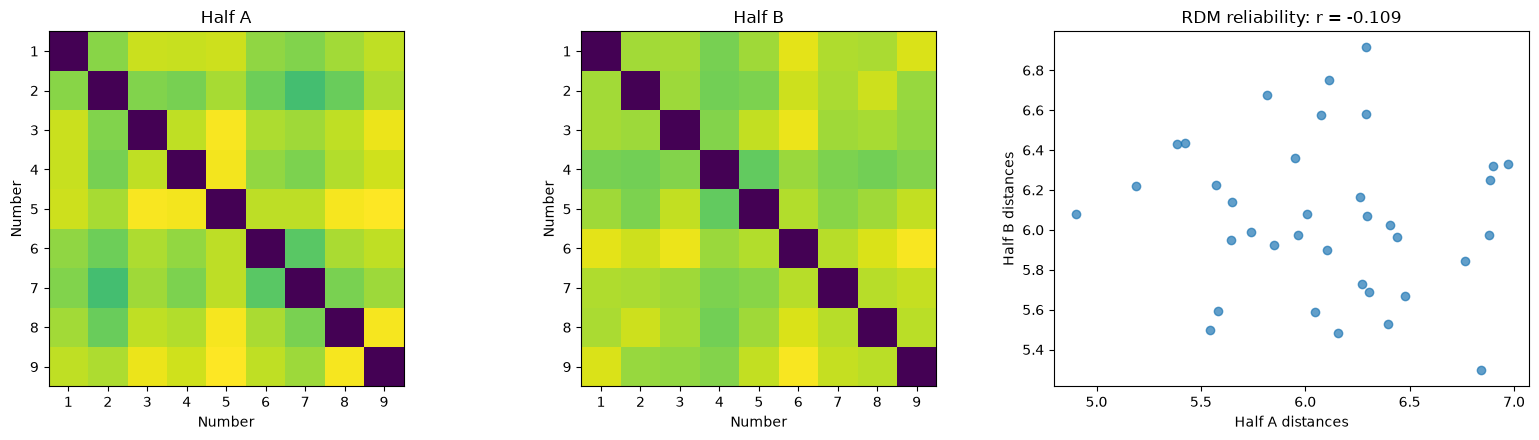

Half A presentations: 247
Half B presentations: 247
Half A mean distance: 6.094686029617874
Half B mean distance: 6.0611024779257
Split-half RDM correlation: -0.10925238321224752


In [49]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.stats import pearsonr
from sklearn.model_selection import GroupShuffleSplit

X = np.asarray(X_original, dtype=float)
labels = np.asarray(y)
trial_groups = np.asarray(groups)
numbers = np.arange(1, 10)

# Split by original arithmetic trial, not presentation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

idx_A, idx_B = next(
    splitter.split(X, labels, groups=trial_groups)
)

def calculate_rdm(indices):
    X_half = X[indices]
    y_half = labels[indices]

    # Every number must be present in the half
    assert np.all(np.isin(numbers, y_half))

    C = np.vstack([
        X_half[y_half == k].mean(axis=0)
        for k in numbers
    ])

    return squareform(pdist(C, metric="euclidean"))

D_A = calculate_rdm(idx_A)
D_B = calculate_rdm(idx_B)

# Compare 36 unique pairwise distances
tri = np.triu_indices(9, k=1)
r, p = pearsonr(D_A[tri], D_B[tri])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

vmax = max(D_A.max(), D_B.max())

for ax, D, title in zip(
    axes[:2],
    [D_A, D_B],
    ["Half A", "Half B"]
):
    im = ax.imshow(D, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.set_xticklabels(numbers)
    ax.set_yticklabels(numbers)
    ax.set_xlabel("Number")
    ax.set_ylabel("Number")
    ax.set_title(title)

axes[2].scatter(D_A[tri], D_B[tri], alpha=0.7)
axes[2].set_xlabel("Half A distances")
axes[2].set_ylabel("Half B distances")
axes[2].set_title(f"RDM reliability: r = {r:.3f}")

plt.tight_layout()
plt.show()

print("Half A presentations:", len(idx_A))
print("Half B presentations:", len(idx_B))
print("Half A mean distance:", D_A[tri].mean())
print("Half B mean distance:", D_B[tri].mean())
print("Split-half RDM correlation:", r)


Do numbers 1–9 occupy a stable, high-dimensional geometric configuration in neural population space?

So far, we have found:
- Affine rank 8 for the estimated centroids.
- Mostly near-zero cross-validated squared distances.
- Sampling-noise contribution comparable to observed squared separation.
- Split-half RDM correlation of −0.109.
These findings are consistent with a geometry that is difficult to estimate reliably from the current data.

In [52]:

import numpy as np
import pandas as pd

# Existing empirical cross-validated squared-distance RDM
D_neural = np.asarray(D_cv, dtype=float)

assert D_neural.shape == (9, 9)

numbers = np.arange(1, 10, dtype=float)

# Theoretical squared-distance RDMs
D_linear = (numbers[:, None] - numbers[None, :])**2

z = np.log(numbers)
D_log = (z[:, None] - z[None, :])**2

D_simplex = np.ones((9, 9))
np.fill_diagonal(D_simplex, 0)

models = {
    "Linear number line": D_linear,
    "Logarithmic number line": D_log,
    "Regular simplex": D_simplex
}

# Extract 36 unique number pairs
upper = np.triu_indices(9, k=1)
y_neural = D_neural[upper]

results = []

for name, D_model in models.items():
    x = D_model[upper]

    # Fit a nonnegative scale, without an intercept
    scale = max(0.0, np.dot(x, y_neural) / np.dot(x, x))
    prediction = scale * x

    mse = np.mean((y_neural - prediction)**2)

    correlation = (
        np.corrcoef(x, y_neural)[0, 1]
        if np.std(x) > 1e-12 else np.nan
    )

    results.append({
        "Model": name,
        "Fitted scale": scale,
        "MSE": mse,
        "Pearson r": correlation
    })

results_df = pd.DataFrame(results).sort_values("MSE")

print("Mean empirical squared distance:", y_neural.mean())
print()
print(results_df.to_string(index=False))


Mean empirical squared distance: -0.0009960123179051387

                  Model  Fitted scale      MSE  Pearson r
     Linear number line           0.0 0.000009   0.005697
Logarithmic number line           0.0 0.000009   0.028506
        Regular simplex           0.0 0.000009        NaN


In [53]:

import numpy as np

# Nine simplex vertices embedded in R^9,
# lying in an 8-dimensional subspace
V = np.eye(9) - np.ones((9, 9)) / 9

# Squared Euclidean distances
D_simplex = np.sum(
    (V[:, None, :] - V[None, :, :])**2,
    axis=2
)

print("Simplex vertex matrix:", V.shape)
print("Affine rank:", np.linalg.matrix_rank(V))
print("Unique off-diagonal squared distances:",
      np.unique(D_simplex[np.triu_indices(9, 1)]))


Simplex vertex matrix: (9, 9)
Affine rank: 8
Unique off-diagonal squared distances: [2.]


In [54]:
import numpy as np

D_simplex = np.ones((9, 9))
np.fill_diagonal(D_simplex, 0)

print(D_simplex)

[[0. 1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 0. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 0. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 0. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 0. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 0. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 0. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1. 0.]]


In [55]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

# Load Bayesian posterior mean matrix
Lambda = np.load("YFU_lambda.npy")

assert Lambda.shape[0] == 9
assert np.isfinite(Lambda).all()

print("Lambda shape:", Lambda.shape)

# Squared Euclidean distances between the 9 number representations
D_lambda = squareform(pdist(Lambda, metric="sqeuclidean"))

# Theoretical geometric models
numbers = np.arange(1, 10, dtype=float)

D_linear = (numbers[:, None] - numbers[None, :])**2

log_numbers = np.log(numbers)
D_log = (log_numbers[:, None] - log_numbers[None, :])**2

D_simplex = np.ones((9, 9))
np.fill_diagonal(D_simplex, 0)

models = {
    "Bayesian Lambda": D_lambda,
    "Linear number line": D_linear,
    "Logarithmic number line": D_log,
    "Regular simplex": D_simplex
}

# Visualize normalized RDMs
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

for ax, (name, D) in zip(axes, models.items()):
    D_plot = D / D.max()

    im = ax.imshow(D_plot, cmap="viridis", vmin=0, vmax=1)

    ax.set_title(name)
    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.set_xticklabels(range(1, 10))
    ax.set_yticklabels(range(1, 10))
    ax.set_xlabel("Number")
    ax.set_ylabel("Number")

plt.tight_layout()
plt.show()

# Summary
upper = np.triu_indices(9, k=1)

print("\nLambda squared-distance statistics:")
print("Mean:", D_lambda[upper].mean())
print("Min: ", D_lambda[upper].min())
print("Max: ", D_lambda[upper].max())


FileNotFoundError: [Errno 2] No such file or directory: 'YFU_lambda.npy'

In [56]:

from pathlib import Path

print("Current directory:", Path.cwd())

# Search the project for saved Lambda files
project_root = Path.cwd().parent

for file in project_root.rglob("*lambda*.npy"):
    print(file)


Current directory: c:\Users\shafi\number-simplex-reproduction\notebooks1
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFF_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFI_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFJ_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFK_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFL_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFM_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFP_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFR_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson\lambda_matrices\YFS_lambda.npy
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisso

In [57]:

import numpy as np
from pathlib import Path
from scipy.spatial.distance import pdist, squareform

# Path relative to notebooks1/
lambda_path = (
    Path.cwd().parent
    / "tables1"
    / "gamma_poisson"
    / "lambda_matrices"
    / "YFU_lambda.npy"
)

Lambda = np.load(lambda_path)

# Validate
print("Lambda shape:", Lambda.shape)
print("Minimum:", Lambda.min())
print("Maximum:", Lambda.max())

assert Lambda.shape[0] == 9
assert np.isfinite(Lambda).all()

# Calculate squared Euclidean RDM
D_lambda = squareform(pdist(Lambda, metric="sqeuclidean"))

print("RDM shape:", D_lambda.shape)
print("Mean squared distance:",
      D_lambda[np.triu_indices(9, 1)].mean())


Lambda shape: (9, 558)
Minimum: 0.1518680342022587
Maximum: 1.4376822090363581
RDM shape: (9, 9)
Mean squared distance: 2.2568600829350367


In [58]:

import numpy as np
import pandas as pd

numbers = np.arange(1, 10, dtype=float)

# Theoretical squared-distance RDMs
D_linear = (numbers[:, None] - numbers[None, :])**2

z = np.log(numbers)
D_log = (z[:, None] - z[None, :])**2

D_simplex = np.ones((9, 9))
np.fill_diagonal(D_simplex, 0)

models = {
    "Linear number line": D_linear,
    "Logarithmic number line": D_log,
    "Regular simplex": D_simplex
}

upper = np.triu_indices(9, k=1)
y = D_lambda[upper]

results = []

for name, D_model in models.items():
    x = D_model[upper]

    # Fit a nonnegative scale without an intercept
    scale = max(0, np.dot(x, y) / np.dot(x, x))
    predicted = scale * x

    mse = np.mean((y - predicted)**2)

    # RDM correlation (undefined for regular simplex)
    r = (
        np.corrcoef(x, y)[0, 1]
        if np.std(x) > 1e-12 else np.nan
    )

    results.append({
        "Model": name,
        "Scale": scale,
        "MSE": mse,
        "Pearson r": r
    })

results_df = pd.DataFrame(results).sort_values("MSE")

print(results_df.to_string(index=False))


                  Model    Scale      MSE  Pearson r
        Regular simplex 2.256860 0.814227        NaN
     Linear number line 0.072269 3.416398   0.043226
Logarithmic number line 0.838447 4.020310  -0.073385


In [59]:

import numpy as np

# 36 unique squared distances
distances = D_lambda[np.triu_indices(9, k=1)]

# Distance regularity
mean_d = distances.mean()
std_d = distances.std()
cv_d = std_d / mean_d

# Center the nine population representations
Lambda_centered = Lambda - Lambda.mean(axis=0)

# Singular values and affine rank
singular_values = np.linalg.svd(
    Lambda_centered, compute_uv=False
)

relative_variance = singular_values**2
relative_variance /= relative_variance.sum()

effective_rank = np.exp(
    -np.sum(
        relative_variance[relative_variance > 0]
        * np.log(relative_variance[relative_variance > 0])
    )
)

print("Mean squared distance:", mean_d)
print("SD of squared distances:", std_d)
print("Coefficient of variation:", cv_d)
print("Affine rank:", np.linalg.matrix_rank(Lambda_centered))
print("Effective rank:", effective_rank)
print("Variance explained:", np.round(relative_variance, 4))


Mean squared distance: 2.2568600829350367
SD of squared distances: 0.9023454156269411
Coefficient of variation: 0.3998233751617623
Affine rank: 8
Effective rank: 5.685888395442755
Variance explained: [0.4577 0.0967 0.0878 0.085  0.0763 0.0724 0.0649 0.0592 0.    ]


In [60]:

# Inspect existing Bayesian hyperparameters
for name in ["alpha", "beta", "m", "tau"]:
    if name in globals():
        print(name, "=", globals()[name])
    else:
        print(name, "not found in notebook variables")


alpha = 31.32151088927648
beta = 139.24162980579783
m not found in notebook variables
tau not found in notebook variables


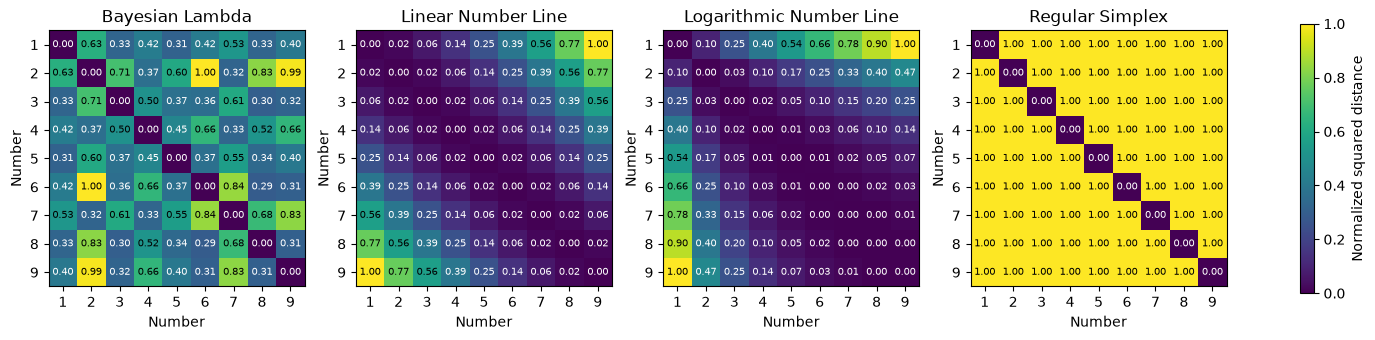

In [61]:

import numpy as np
import matplotlib.pyplot as plt

models = {
    "Bayesian Lambda": D_lambda,
    "Linear Number Line": D_linear,
    "Logarithmic Number Line": D_log,
    "Regular Simplex": D_simplex
}

fig, axes = plt.subplots(1, 4, figsize=(19, 5))

for ax, (name, D) in zip(axes, models.items()):

    # Normalize each RDM for visual comparison
    D_norm = D / D.max()

    im = ax.imshow(
        D_norm,
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    # Display normalized values inside pixels
    for i in range(9):
        for j in range(9):
            value = D_norm[i, j]
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                fontsize=7,
                color="white" if value < 0.5 else "black"
            )

    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.set_xticklabels(range(1, 10))
    ax.set_yticklabels(range(1, 10))

    ax.set_xlabel("Number")
    ax.set_ylabel("Number")
    ax.set_title(name)

fig.colorbar(im, ax=axes, shrink=0.7, label="Normalized squared distance")
plt.show()


OBSERVED YFU BAYESIAN GEOMETRY
---------------------------------------------
affine_rank              : 8.000000
effective_rank           : 5.685888
distance_cv              : 0.399823
largest_fraction         : 0.457709
mean_squared_distance    : 2.256860

Anisotropic covariance rank: 8

Simulation complete: 5000 per control

GEOMETRY COMPARISON
          Metric  Observed  Isotropic mean Isotropic 95% interval  Anisotropic mean Anisotropic 95% interval
  effective_rank  5.685888        7.937555       [7.9056, 7.9635]          3.861008         [2.6333, 5.0291]
     distance_cv  0.399823        0.055257       [0.0400, 0.0728]          0.596930         [0.4014, 0.8705]
largest_fraction  0.457709        0.150193       [0.1425, 0.1600]          0.528502         [0.3457, 0.7261]

MONTE CARLO TAIL PROPORTIONS
(Descriptive, not formal p-values)

effective_rank
  Isotropic:   lower=0.0000, upper=1.0000
  Anisotropic: lower=1.0000, upper=0.0000

distance_cv
  Isotropic:   lower=1.0000, upper=0.

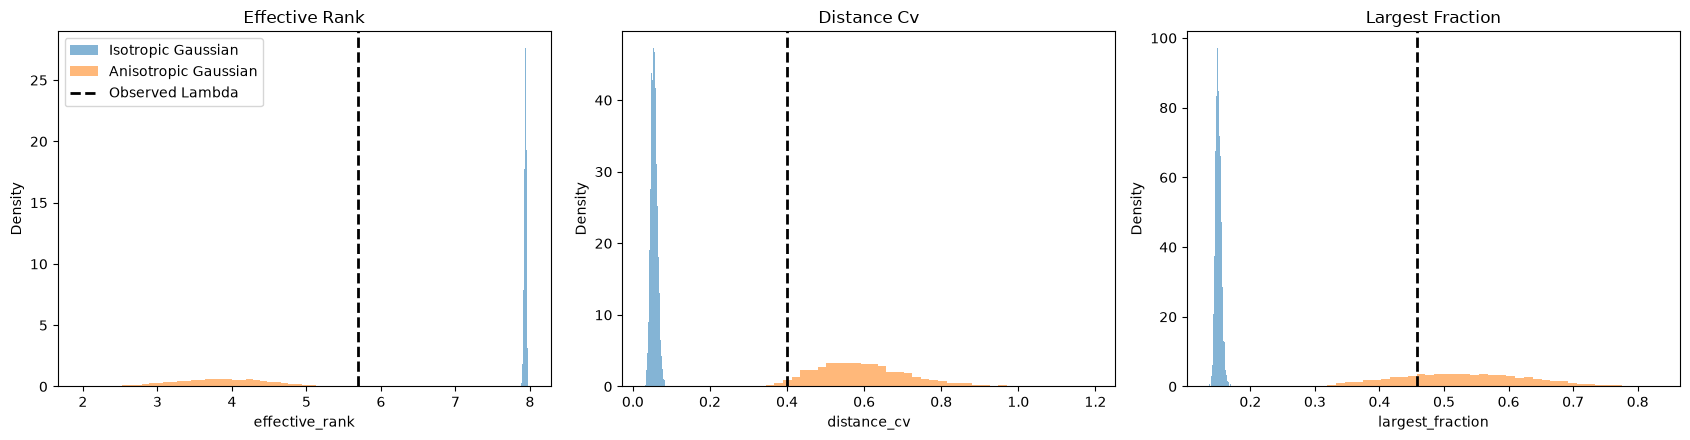

In [62]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. SETTINGS AND VALIDATION
# ============================================================

N_SIM = 5000
SEED = 42

rng = np.random.default_rng(SEED)

L = np.asarray(Lambda, dtype=float)

assert L.shape == (9, 558), "Expected Lambda shape (9, 558)"
assert np.isfinite(L).all(), "Lambda contains invalid values"

n_numbers, n_features = L.shape
upper = np.triu_indices(n_numbers, k=1)

# ============================================================
# 2. GEOMETRY STATISTICS
# ============================================================

def geometry_statistics(X):
    """
    X: (9, 558) matrix of population representations.

    Returns:
        affine_rank
        effective_rank
        distance_cv
        largest_variance_fraction
        mean_squared_distance
    """

    X = np.asarray(X, dtype=float)

    # Center the 9 population vectors
    Xc = X - X.mean(axis=0, keepdims=True)

    # Singular values of centered representation
    s = np.linalg.svd(Xc, compute_uv=False)

    # Numerical affine rank
    rank = np.linalg.matrix_rank(Xc)

    # Eigenvalue proportions of between-number covariance
    eigenvalues = s**2

    total = eigenvalues.sum()

    if total <= 0:
        raise ValueError("Degenerate configuration")

    p = eigenvalues / total
    p_positive = p[p > 1e-15]

    # Effective rank (entropy-based)
    effective_rank = np.exp(
        -np.sum(p_positive * np.log(p_positive))
    )

    largest_fraction = p.max()

    # Squared Euclidean distance matrix
    squared_norms = np.sum(Xc**2, axis=1)

    D = (
        squared_norms[:, None]
        + squared_norms[None, :]
        - 2 * Xc @ Xc.T
    )

    D = np.maximum(D, 0)

    distances = D[upper]

    mean_distance = distances.mean()

    distance_cv = distances.std(ddof=0) / mean_distance

    return {
        "affine_rank": rank,
        "effective_rank": effective_rank,
        "distance_cv": distance_cv,
        "largest_fraction": largest_fraction,
        "mean_squared_distance": mean_distance
    }


# ============================================================
# 3. OBSERVED GEOMETRY
# ============================================================

observed = geometry_statistics(L)

print("OBSERVED YFU BAYESIAN GEOMETRY")
print("-" * 45)

for key, value in observed.items():
    print(f"{key:25s}: {value:.6f}")


# ============================================================
# 4. CONSTRUCT RANDOM CONTROLS
# ============================================================

# Center observed Lambda
L_centered = L - L.mean(axis=0, keepdims=True)

# SVD provides feature-space principal directions
_, s_obs, Vt = np.linalg.svd(
    L_centered,
    full_matrices=False
)

# Eigenvalues of sample covariance across 9 number vectors
cov_eigenvalues = s_obs**2 / (n_numbers - 1)

# Retain only nonzero modes
positive = cov_eigenvalues > (
    cov_eigenvalues.max() * 1e-12
)

cov_eigenvalues = cov_eigenvalues[positive]
Vt = Vt[positive]

print("\nAnisotropic covariance rank:", len(cov_eigenvalues))


def match_distance_scale(X, target_mean):
    """
    Rescale configuration so its mean squared
    pairwise distance matches the observed value.
    """
    stats = geometry_statistics(X)

    factor = np.sqrt(
        target_mean / stats["mean_squared_distance"]
    )

    return X * factor


def generate_isotropic():
    """
    Nine independent isotropic Gaussian points
    in the full 558-dimensional feature space.
    """
    X = rng.normal(
        loc=0,
        scale=1,
        size=(n_numbers, n_features)
    )

    return match_distance_scale(
        X, observed["mean_squared_distance"]
    )


def generate_anisotropic():
    """
    Nine independent Gaussian points sampled from
    the feature covariance estimated from Lambda.

    This preserves observed covariance anisotropy.
    It is a descriptive benchmark, not a pure null.
    """

    Z = rng.normal(
        size=(n_numbers, len(cov_eigenvalues))
    )

    X = (
        Z * np.sqrt(cov_eigenvalues)
    ) @ Vt

    return match_distance_scale(
        X, observed["mean_squared_distance"]
    )


# ============================================================
# 5. MONTE CARLO SIMULATIONS
# ============================================================

isotropic_results = []
anisotropic_results = []

for simulation in range(N_SIM):

    X_iso = generate_isotropic()
    X_aniso = generate_anisotropic()

    isotropic_results.append(
        geometry_statistics(X_iso)
    )

    anisotropic_results.append(
        geometry_statistics(X_aniso)
    )

df_iso = pd.DataFrame(isotropic_results)
df_aniso = pd.DataFrame(anisotropic_results)

print("\nSimulation complete:", N_SIM, "per control")


# ============================================================
# 6. SUMMARY TABLE
# ============================================================

metrics = [
    "effective_rank",
    "distance_cv",
    "largest_fraction"
]

summary = []

for metric in metrics:

    summary.append({
        "Metric": metric,
        "Observed": observed[metric],
        "Isotropic mean": df_iso[metric].mean(),
        "Isotropic 95% interval": (
            f"[{df_iso[metric].quantile(0.025):.4f}, "
            f"{df_iso[metric].quantile(0.975):.4f}]"
        ),
        "Anisotropic mean": df_aniso[metric].mean(),
        "Anisotropic 95% interval": (
            f"[{df_aniso[metric].quantile(0.025):.4f}, "
            f"{df_aniso[metric].quantile(0.975):.4f}]"
        )
    })

summary_df = pd.DataFrame(summary)

print("\nGEOMETRY COMPARISON")
print(summary_df.to_string(index=False))


# ============================================================
# 7. MONTE CARLO TAIL PROPORTIONS
# ============================================================

print("\nMONTE CARLO TAIL PROPORTIONS")
print("(Descriptive, not formal p-values)")

for metric in metrics:

    obs = observed[metric]

    iso_lower = np.mean(df_iso[metric] <= obs)
    iso_upper = np.mean(df_iso[metric] >= obs)

    aniso_lower = np.mean(df_aniso[metric] <= obs)
    aniso_upper = np.mean(df_aniso[metric] >= obs)

    print(f"\n{metric}")
    print(
        f"  Isotropic:   lower={iso_lower:.4f}, "
        f"upper={iso_upper:.4f}"
    )
    print(
        f"  Anisotropic: lower={aniso_lower:.4f}, "
        f"upper={aniso_upper:.4f}"
    )


# ============================================================
# 8. VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5)
)

for ax, metric in zip(axes, metrics):

    ax.hist(
        df_iso[metric],
        bins=40,
        alpha=0.55,
        density=True,
        label="Isotropic Gaussian"
    )

    ax.hist(
        df_aniso[metric],
        bins=40,
        alpha=0.55,
        density=True,
        label="Anisotropic Gaussian"
    )

    ax.axvline(
        observed[metric],
        color="black",
        linewidth=2,
        linestyle="--",
        label="Observed Lambda"
    )

    ax.set_xlabel(metric)
    ax.set_ylabel("Density")
    ax.set_title(metric.replace("_", " ").title())

axes[0].legend()

plt.tight_layout()
plt.show()


In [64]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform

# ============================================================
# 1. SETTINGS
# ============================================================

rng = np.random.default_rng(42)

n_numbers = 9
n_features = 558

class_counts = np.array(
    [53, 67, 52, 62, 51, 48, 65, 49, 47]
)

alpha = 31.32151088927648
beta = 139.24162980579783

L_obs = np.asarray(Lambda, dtype=float)

assert L_obs.shape == (9, 558)
assert class_counts.sum() == 494

# Observed mean squared distance
target_distance = pdist(
    L_obs, metric="sqeuclidean"
).mean()

# Observed feature-wise baseline
baseline = L_obs.mean(axis=0)

print("Target mean squared distance:", target_distance)
print("Baseline range:", baseline.min(), baseline.max())


# ============================================================
# 2. CONSTRUCT LOW-DIMENSIONAL GROUND TRUTHS
# ============================================================

numbers = np.arange(1, 10, dtype=float)

# Model 1: Linear number line
Z_linear = numbers[:, None]

# Model 2: Logarithmic number line
Z_log = np.log(numbers)[:, None]

# Model 3: Curved manifold (parabolic trajectory)
t = np.linspace(-1, 1, 9)
Z_curved = np.column_stack([t, 1.5 * t**2])

# Model 4: Regular simplex
Z_simplex = np.eye(9) - np.ones((9, 9)) / 9

# Model 5: Irregular simplex
# Fixed random deformation of a regular simplex
A = rng.normal(size=(9, 8))
Z_irregular = Z_simplex @ A

ground_truths = {
    "Linear": Z_linear,
    "Logarithmic": Z_log,
    "Curved": Z_curved,
    "Regular simplex": Z_simplex,
    "Irregular simplex": Z_irregular
}


# ============================================================
# 3. EMBED INTO 558 NEURAL FEATURES
# ============================================================

def embed_geometry(Z, baseline, target_distance, rng):
    """
    Embed nine geometric points into 558 neural features.

    Preserve pairwise distances up to a common scale,
    then shift the embedded points to nonnegative means.
    """

    Z = np.asarray(Z, dtype=float)

    # Center geometry
    Zc = Z - Z.mean(axis=0, keepdims=True)

    # Random orthonormal embedding into 558 dimensions
    A = rng.normal(size=(558, Zc.shape[1]))
    Q, _ = np.linalg.qr(A)

    X = Zc @ Q.T

    # Match observed mean squared pairwise distance
    current_distance = pdist(
        X, metric="sqeuclidean"
    ).mean()

    X *= np.sqrt(target_distance / current_distance)

    # Add observed feature-wise baseline
    X += baseline[None, :]

    # Ensure nonnegative Poisson means.
    # A common feature-wise shift preserves all distances.
    feature_min = X.min(axis=0)
    correction = np.maximum(0, 0.01 - feature_min)

    X += correction[None, :]

    return X


true_means = {}

for name, Z in ground_truths.items():

    M = embed_geometry(
        Z,
        baseline,
        target_distance,
        rng
    )

    true_means[name] = M


# ============================================================
# 4. VALIDATION
# ============================================================

rows = []

for name, M in true_means.items():

    D = squareform(
        pdist(M, metric="sqeuclidean")
    )

    rank = np.linalg.matrix_rank(
        M - M.mean(axis=0)
    )

    rows.append({
        "Model": name,
        "Shape": str(M.shape),
        "Affine rank": rank,
        "Mean squared distance": pdist(
            M, metric="sqeuclidean"
        ).mean(),
        "Minimum Poisson mean": M.min()
    })

summary = pd.DataFrame(rows)

print("\nGROUND-TRUTH GEOMETRIES")
print(summary.to_string(index=False))


Target mean squared distance: 2.2568600829350367
Baseline range: 0.16211413133041933 1.2247967807085423

GROUND-TRUTH GEOMETRIES
            Model    Shape  Affine rank  Mean squared distance  Minimum Poisson mean
           Linear (9, 558)            1                2.25686              0.043380
      Logarithmic (9, 558)            1                2.25686              0.010000
           Curved (9, 558)            2                2.25686              0.010000
  Regular simplex (9, 558)            8                2.25686              0.043312
Irregular simplex (9, 558)            8                2.25686              0.022478


In [65]:

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.spatial.distance import pdist

# ============================================================
# 1. SETTINGS
# ============================================================

rng = np.random.default_rng(2026)

class_counts = np.array(
    [53, 67, 52, 62, 51, 48, 65, 49, 47]
)

assert class_counts.sum() == 494
assert len(true_means) == 5

# ============================================================
# 2. GAMMA-POISSON HYPERPARAMETER ESTIMATION
# ============================================================

def estimate_alpha_beta(X, y):
    """
    Empirical-Bayes estimation of shared alpha and beta.

    Prior:
        lambda_kj ~ Gamma(alpha, beta)

    Likelihood:
        X_ij | lambda_kj ~ Poisson(lambda_kj)

    Gamma uses shape-rate parameterization.

    Optimize the marginal likelihood of class-feature
    count totals.
    """

    classes = np.arange(9)

    S = np.vstack([
        X[y == k].sum(axis=0)
        for k in classes
    ])

    n = np.array([
        np.sum(y == k)
        for k in classes
    ], dtype=float)[:, None]

    # Marginal likelihood, omitting terms independent
    # of alpha and beta
    def negative_log_marginal(log_params):

        alpha, beta = np.exp(log_params)

        value = (
            gammaln(alpha + S)
            - gammaln(alpha)
            + alpha * np.log(beta)
            - (alpha + S) * np.log(beta + n)
        )

        return -np.sum(value)

    pooled_mean = X.mean()
    initial_alpha = max(pooled_mean * 10, 0.1)
    initial_beta = 10.0

    result = minimize(
        negative_log_marginal,
        x0=np.log([initial_alpha, initial_beta]),
        method="L-BFGS-B",
        bounds=[
            (np.log(1e-4), np.log(1e5)),
            (np.log(1e-4), np.log(1e5))
        ]
    )

    if not result.success:
        raise RuntimeError(result.message)

    alpha, beta = np.exp(result.x)

    return alpha, beta


# ============================================================
# 3. POSTERIOR MEAN
# ============================================================

def posterior_mean_matrix(X, y, alpha, beta):

    Lambda_hat = np.zeros((9, X.shape[1]))

    for k in range(9):

        Xk = X[y == k]

        S = Xk.sum(axis=0)
        n = len(Xk)

        Lambda_hat[k] = (
            alpha + S
        ) / (
            beta + n
        )

    return Lambda_hat


# ============================================================
# 4. GEOMETRY METRICS
# ============================================================

def geometry_metrics(M):

    M_centered = M - M.mean(axis=0)

    singular_values = np.linalg.svd(
        M_centered,
        compute_uv=False
    )

    eigenvalues = singular_values**2

    p = eigenvalues / eigenvalues.sum()
    p = p[p > 1e-15]

    effective_rank = np.exp(
        -np.sum(p * np.log(p))
    )

    distances = pdist(
        M, metric="sqeuclidean"
    )

    return {
        "effective_rank": effective_rank,
        "distance_cv": distances.std() / distances.mean(),
        "mean_squared_distance": distances.mean()
    }


# ============================================================
# 5. SIMULATE AND RECOVER
# ============================================================

results = []
recovered_means = {}

for model_name, M_true in true_means.items():

    # Generate 494 synthetic presentations
    X_parts = []
    y_parts = []

    for k, n_trials in enumerate(class_counts):

        Xk = rng.poisson(
            lam=M_true[k],
            size=(n_trials, M_true.shape[1])
        )

        X_parts.append(Xk)
        y_parts.append(
            np.full(n_trials, k)
        )

    X_sim = np.vstack(X_parts)
    y_sim = np.concatenate(y_parts)

    # Estimate new hyperparameters
    alpha_hat, beta_hat = estimate_alpha_beta(
        X_sim, y_sim
    )

    # Recover Bayesian posterior means
    M_hat = posterior_mean_matrix(
        X_sim, y_sim,
        alpha_hat, beta_hat
    )

    recovered_means[model_name] = M_hat

    # True and recovered RDMs
    D_true = pdist(
        M_true, metric="sqeuclidean"
    )

    D_hat = pdist(
        M_hat, metric="sqeuclidean"
    )

    # Compare distance patterns
    if D_true.std() > 1e-12 and D_hat.std() > 1e-12:
        rdm_r = np.corrcoef(
            D_true, D_hat
        )[0, 1]
    else:
        rdm_r = np.nan

    # Scale-invariant RDM recovery error
    scale = np.dot(D_true, D_hat) / np.dot(D_hat, D_hat)
    rdm_error = np.mean(
        (D_true - scale * D_hat)**2
    ) / np.mean(D_true**2)

    true_stats = geometry_metrics(M_true)
    recovered_stats = geometry_metrics(M_hat)

    results.append({
        "Model": model_name,
        "Alpha": alpha_hat,
        "Beta": beta_hat,
        "True effective rank": true_stats["effective_rank"],
        "Recovered effective rank": recovered_stats["effective_rank"],
        "True distance CV": true_stats["distance_cv"],
        "Recovered distance CV": recovered_stats["distance_cv"],
        "RDM correlation": rdm_r,
        "Normalized RDM error": rdm_error
    })


# ============================================================
# 6. RESULTS
# ============================================================

recovery_df = pd.DataFrame(results)

print("\nGAMMA-POISSON GEOMETRY RECOVERY")
print("=" * 65)

print(
    recovery_df.round(4).to_string(index=False)
)



GAMMA-POISSON GEOMETRY RECOVERY
            Model  Alpha   Beta  True effective rank  Recovered effective rank  True distance CV  Recovered distance CV  RDM correlation  Normalized RDM error
           Linear 3.8577 9.3035               1.0000                    6.9741            1.0583                 0.2544           0.9382                0.3049
      Logarithmic 3.8295 9.1723               1.0000                    7.0595            1.2279                 0.2736           0.9449                0.3561
           Curved 3.9157 9.3565               1.9740                    7.3425            0.7914                 0.1965           0.9579                0.2184
  Regular simplex 3.8355 9.2308               8.0000                    7.9179            0.0000                 0.0786              NaN                0.0061
Irregular simplex 3.8739 9.2641               4.6948                    7.7338            0.4175                 0.1196           0.8174                0.0905


In [66]:

from pathlib import Path

root = Path.cwd().parent
tables = root / "tables1"

keywords = (
    "lda", "component", "projection",
    "neuron", "select", "tuned",
    "temporal", "population"
)

print("Project root:", root)
print("Tables directory exists:", tables.exists())

matches = []

if tables.exists():
    for path in tables.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()

        if "yfu" in name and any(k in name for k in keywords):
            matches.append(path)

print(f"\nFound {len(matches)} candidate YFU files:\n")

for path in sorted(matches):
    print(path.relative_to(root))


Project root: c:\Users\shafi\number-simplex-reproduction
Tables directory exists: True

Found 8 candidate YFU files:

tables1\population_decoding\YFU_population_folds.csv
tables1\population_decoding\YFU_population_summary.csv
tables1\YFU_arithmetic_temporal_counts_100ms.csv
tables1\YFU_arithmetic_temporal_rates_100ms.csv
tables1\YFU_count_vs_temporal_geometry_comparison.csv
tables1\YFU_lda_vs_logistic.csv
tables1\YFU_neuron43_lda_vs_logistic.csv
tables1\YFU_single_neuron_number_selectivity.csv


In [67]:

import pandas as pd
from pathlib import Path

root = Path.cwd().parent

file = root / "tables1" / "YFU_single_neuron_number_selectivity.csv"

df = pd.read_csv(file)

print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isna().sum())


Shape: (78, 8)

Column names:
['neuron', 'preferred_number', 'peak_rate_Hz', 'modulation_index', 'H_statistic', 'p_value', 'p_fdr', 'significant_fdr']

First 5 rows:


,neuron,preferred_number,peak_rate_Hz,modulation_index,H_statistic,p_value,p_fdr,significant_fdr
0,61,3,2.820513,0.213328,19.513872,0.012340,0.528931,False
1,69,1,13.459119,0.075944,19.223973,0.013707,0.528931,False
2,33,9,8.888889,0.117078,18.120155,0.020343,0.528931,False
3,19,8,10.340136,0.103133,16.331787,0.037870,0.699567,False
4,42,3,7.307692,0.095452,14.808953,0.062968,0.699567,False



Missing values:
neuron              0
preferred_number    0
peak_rate_Hz        0
modulation_index    0
H_statistic         0
p_value             0
p_fdr               0
significant_fdr     0
dtype: int64


In [68]:

from pathlib import Path

root = Path.cwd().parent

keywords = [
    "lda", "decoding", "tuned", "selective",
    "component", "projection", "gamma",
    "temporal", "population"
]

extensions = {".csv", ".npy", ".npz", ".pkl", ".parquet"}

matches = []

for folder in ["tables", "tables1"]:
    directory = root / folder

    if not directory.exists():
        continue

    for path in directory.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            if any(k in path.name.lower() for k in keywords):
                matches.append(path)

print(f"Found {len(matches)} candidate files:\n")

for path in sorted(matches):
    print(path.relative_to(root))


Found 116 candidate files:

tables\arithmetic_population_fr_vs_temporal_60ms.csv
tables\arithmetic_population_fr_vs_temporal_60ms_permutation.csv
tables\arithmetic_population_lda_components_60ms_permutation.csv
tables\arithmetic_population_lda_components_group_null.csv
tables\arithmetic_population_temporal_minus_fr_group_null.csv
tables\arithmetic_population_three_representations.csv
tables\arithmetic_subjectwise_population_decoding_60ms.csv
tables\arithmetic_subjectwise_population_decoding_60ms_permutation.csv
tables\arithmetic_temporal_5000perm_checkpoint.csv
tables\arithmetic_temporal_coding_proportion_by_subject.csv
tables\arithmetic_temporal_coding_proportion_subject_bootstrap.csv
tables\arithmetic_temporal_floor_neurons_5000perm.csv
tables\arithmetic_temporal_floor_neurons_5000perm_checkpoint.csv
tables\arithmetic_temporal_mtl_neuron_results.csv
tables\arithmetic_temporal_mtl_neuron_results_FDR_fresh.csv
tables\arithmetic_temporal_neurons_at_200perm_floor.csv
tables\arithmetic_te

In [69]:

import pandas as pd
from pathlib import Path

root = Path.cwd().parent

files = [
    "tables/figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv",
    "tables1/figure1N_YFU_decoding.csv",
    "tables/figure1G_YFU_hpc43_all_LDA_components.csv",
    "tables/arithmetic_temporal_mtl_neuron_results.csv",
]

for filename in files:
    path = root / filename

    print("\n" + "=" * 75)
    print(filename)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    display(df.head(3))



tables/figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv
Shape: (554, 15)
Columns: ['subject', 'region', 'neuron_id', 'paper_unit', 'n_presentations', 'temporal_accuracy', 'best_bin_ms', 'best_gamma', 'shuffle_mean_accuracy', 'shuffle_95', 'p_value', 'temporal_coding', 'n_valid_shuffles', 'q_value', 'temporal_coding_FDR']

First 3 rows:


,subject,region,neuron_id,paper_unit,n_presentations,temporal_accuracy,best_bin_ms,best_gamma,shuffle_mean_accuracy,shuffle_95,p_value,temporal_coding,n_valid_shuffles,q_value,temporal_coding_FDR
0,YFF,ent,8,9,109,0.155963,60.0,0.8,0.109358,0.165138,0.129353,False,200,0.253625,False
1,YFF,hpc,9,10,109,0.165138,900.0,0.2,0.105459,0.155963,0.049751,True,200,0.169649,False
2,YFF,hpc,10,11,109,0.183486,75.0,0.8,0.110550,0.156881,0.039801,True,200,0.166800,False



tables1/figure1N_YFU_decoding.csv
Shape: (62, 12)
Columns: ['subject', 'neuron', 'region', 'mean_firing_rate_hz', 'n_presentations', 'min_class_count', 'n_splits', 'FR_accuracy', 'TC_accuracy', 'best_bin_ms', 'best_gamma', 'status']

First 3 rows:


,subject,neuron,region,mean_firing_rate_hz,n_presentations,min_class_count,n_splits,FR_accuracy,TC_accuracy,best_bin_ms,best_gamma,status
0,YFU,1,amy,4.426451,494,47,10,0.115385,0.121457,225,0.5,success
1,YFU,2,amy,14.709852,494,47,10,0.107287,0.129555,90,0.8,success
2,YFU,3,amy,9.592892,494,47,10,0.082996,0.133603,450,0.2,success



tables/figure1G_YFU_hpc43_all_LDA_components.csv
Shape: (6, 8)
Columns: ['bin', 'time_ms', 'LDA1', 'LDA2', 'LDA3', 'LDA4', 'LDA5', 'LDA6']

First 3 rows:


,bin,time_ms,LDA1,LDA2,LDA3,LDA4,LDA5,LDA6
0,1,125,0.059285,-0.126129,-0.677911,-0.349532,-0.527969,0.231476
1,2,275,-0.121261,-0.893109,0.337475,-0.403351,-0.089506,-0.148936
2,3,425,-0.185358,0.142518,0.248648,-0.260827,0.214930,0.918168



tables/arithmetic_temporal_mtl_neuron_results.csv
Shape: (554, 14)
Columns: ['subject', 'neuron', 'region_raw', 'region', 'n_trials', 'n_presentations', 'best_bin_ms', 'best_gamma', 'temporal_accuracy', 'permutation_p', 'n_perm_equal_or_better', 'coding', 'valid', 'invalid_reason']

First 3 rows:


,subject,neuron,region_raw,region,n_trials,n_presentations,best_bin_ms,best_gamma,temporal_accuracy,permutation_p,n_perm_equal_or_better,coding,valid,invalid_reason
0,YFF,8,ent,ENT,100,109,60.0,0.5,0.146789,0.288557,57.0,False,True,NaN
1,YFF,9,hpc,HPC,100,109,90.0,0.2,0.183486,0.044776,8.0,True,True,NaN
2,YFF,10,hpc,HPC,100,109,75.0,0.5,0.128440,0.318408,63.0,False,True,NaN



import pandas as pd
from pathlib import Path

root = Path.cwd().parent

path = root / "tables" / "figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv"
df = pd.read_csv(path)

yfu = df[df["subject"] == "YFU"].copy()

selected = yfu[
    yfu["p_value"].notna() &
    (yfu["p_value"] <= 0.125)
].copy()

selected = selected.sort_values("neuron_id")

print("YFU total neurons:", len(yfu))
print("YFU selected neurons (p <= 0.125):", len(selected))

print("\nSelected neuron IDs:")
print(selected["neuron_id"].tolist())

print("\nOptimized bin-size distribution:")
print(selected["best_bin_ms"].value_counts().sort_index())

print("\nOptimized gamma distribution:")
print(selected["best_gamma"].value_counts().sort_index())

print("\nSelected neuron details:")
display(
    selected[
        [
            "neuron_id", "region", "temporal_accuracy",
            "best_bin_ms", "best_gamma", "p_value"
        ]
    ].reset_index(drop=True)
)


In [70]:

import pandas as pd
from pathlib import Path

root = Path.cwd().parent

path = root / "tables" / "figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv"
df = pd.read_csv(path)

yfu = df[df["subject"] == "YFU"].copy()

selected = yfu[
    yfu["p_value"].notna() &
    (yfu["p_value"] <= 0.125)
].copy()

selected = selected.sort_values("neuron_id")

print("YFU total neurons:", len(yfu))
print("YFU selected neurons (p <= 0.125):", len(selected))

print("\nSelected neuron IDs:")
print(selected["neuron_id"].tolist())

print("\nOptimized bin-size distribution:")
print(selected["best_bin_ms"].value_counts().sort_index())

print("\nOptimized gamma distribution:")
print(selected["best_gamma"].value_counts().sort_index())

print("\nSelected neuron details:")
display(
    selected[
        [
            "neuron_id", "region", "temporal_accuracy",
            "best_bin_ms", "best_gamma", "p_value"
        ]
    ].reset_index(drop=True)
)


YFU total neurons: 62
YFU selected neurons (p <= 0.125): 37

Selected neuron IDs:
[1, 3, 7, 20, 21, 22, 23, 25, 27, 28, 29, 30, 31, 32, 33, 36, 37, 38, 39, 41, 42, 43, 45, 48, 49, 51, 52, 53, 54, 55, 56, 60, 61, 64, 66, 67, 69]

Optimized bin-size distribution:
best_bin_ms
60.0     8
75.0     3
90.0     1
100.0    7
150.0    6
180.0    4
225.0    1
300.0    1
450.0    3
900.0    3
Name: count, dtype: int64

Optimized gamma distribution:
best_gamma
0.2    18
0.5     8
0.8    11
Name: count, dtype: int64

Selected neuron details:


,neuron_id,region,temporal_accuracy,best_bin_ms,best_gamma,p_value
0,1,amy,0.135628,150.0,0.2,0.094527
1,3,amy,0.155870,450.0,0.5,0.009950
2,7,amy,0.135628,90.0,0.8,0.104478
3,20,hpc,0.135628,60.0,0.2,0.069652
4,21,hpc,0.137652,900.0,0.2,0.049751
5,22,hpc,0.141700,900.0,0.2,0.034826
6,23,hpc,0.143725,100.0,0.2,0.039801
7,25,hpc,0.129555,180.0,0.8,0.094527
8,27,hpc,0.129555,180.0,0.5,0.119403
9,28,hpc,0.143725,60.0,0.8,0.039801


In [71]:

import pandas as pd

root = Path.cwd().parent

a = pd.read_csv(
    root / "tables" /
    "figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv"
)

b = pd.read_csv(
    root / "tables1" /
    "figure1N_YFU_decoding.csv"
)

a = a[a["subject"] == "YFU"].copy()

print("Table A neuron IDs:")
print(sorted(a["neuron_id"].dropna().astype(int).tolist()))

print("\nTable B neuron IDs:")
print(sorted(b["neuron"].dropna().astype(int).tolist()))

print("\nNeuron 43 in both tables:")

display(a[a["neuron_id"] == 43])
display(b[b["neuron"] == 43])


Table A neuron IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69]

Table B neuron IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70]

Neuron 43 in both tables:


,subject,region,neuron_id,paper_unit,n_presentations,temporal_accuracy,best_bin_ms,best_gamma,shuffle_mean_accuracy,shuffle_95,p_value,temporal_coding,n_valid_shuffles,q_value,temporal_coding_FDR
527,YFU,amy,43,44,494,0.15587,180.0,0.2,0.111589,0.135729,0.014925,True,200,0.148982,False


,subject,neuron,region,mean_firing_rate_hz,n_presentations,min_class_count,n_splits,FR_accuracy,TC_accuracy,best_bin_ms,best_gamma,status
34,YFU,43,hpc,6.693657,494,47,10,0.121457,0.163968,150,0.2,success


In [72]:

import pandas as pd

a = pd.read_csv(
    root / "tables" /
    "figure1_arithmetic_TEMPORAL_all554_sklearnGamma_with_FDR.csv"
)

b = pd.read_csv(
    root / "tables1" / "figure1N_YFU_decoding.csv"
)

a = a[a["subject"] == "YFU"].copy()

a["neuron_B"] = a["neuron_id"] + 1

merged = a.merge(
    b,
    left_on="neuron_B",
    right_on="neuron",
    suffixes=("_A", "_B"),
    how="left",
    validate="one_to_one"
)

print("Total neurons:", len(merged))
print("Matched neurons:", merged["neuron"].notna().sum())

region_match = (
    merged["region_A"].str.lower()
    == merged["region_B"].str.lower()
)

print("Region matches:", region_match.sum())
print("Region mismatches:", (~region_match).sum())

print("\nMismatched rows:")
display(
    merged.loc[
        ~region_match,
        ["neuron_id", "neuron_B", "region_A", "region_B"]
    ]
)

print("\nSelected neurons:")
display(
    merged.loc[
        merged["p_value"] <= 0.125,
        [
            "neuron_id", "neuron_B", "region_A",
            "best_bin_ms_A", "best_gamma_A", "p_value"
        ]
    ]
)


Total neurons: 62
Matched neurons: 62
Region matches: 62
Region mismatches: 0

Mismatched rows:


,neuron_id,neuron_B,region_A,region_B



Selected neurons:


,neuron_id,neuron_B,region_A,best_bin_ms_A,best_gamma_A,p_value
1,1,2,amy,150.0,0.2,0.094527
3,3,4,amy,450.0,0.5,0.009950
7,7,8,amy,90.0,0.8,0.104478
12,20,21,hpc,60.0,0.2,0.069652
13,21,22,hpc,900.0,0.2,0.049751
14,22,23,hpc,900.0,0.2,0.034826
15,23,24,hpc,100.0,0.2,0.039801
17,25,26,hpc,180.0,0.8,0.094527
19,27,28,hpc,180.0,0.5,0.119403
20,28,29,hpc,60.0,0.8,0.039801


In [73]:

import numpy as np

rng = np.random.default_rng(42)

# Experimental dimensions
numbers = np.arange(1, 10)
n_neurons = 62
n_bins = 15  # Fine temporal grid: 15 × 60 ms = 900 ms

# Centered linear number representation
z = numbers.astype(float) - numbers.mean()

# Synthetic baseline expected counts per 60 ms bin
baseline = rng.uniform(0.2, 1.2, size=(n_neurons, n_bins))

# Neuron-specific temporal tuning coefficients
weights = rng.normal(0, 0.08, size=(n_neurons, n_bins))

# Expected spike counts: number × neuron × temporal bin
lam = baseline[None, :, :] + z[:, None, None] * weights[None, :, :]

# Ensure positivity without clipping the tuning geometry
assert np.all(lam > 0), "Negative expected counts: adjust tuning coefficients."

# Flatten population responses
ground_truth = lam.reshape(9, -1)

# Center across the nine numerical stimuli
ground_truth_centered = ground_truth - ground_truth.mean(axis=0)

# Singular values and numerical rank
singular_values = np.linalg.svd(
    ground_truth_centered, compute_uv=False
)

rank = np.linalg.matrix_rank(ground_truth_centered, tol=1e-10)

print("Lambda shape:", lam.shape)
print("Ground-truth population matrix:", ground_truth.shape)
print("Minimum lambda:", lam.min())
print("Maximum lambda:", lam.max())
print("Ground-truth affine rank:", rank)
print("Singular values:", np.round(singular_values, 8))


AssertionError: Negative expected counts: adjust tuning coefficients.

In [74]:

import numpy as np

rng = np.random.default_rng(42)

numbers = np.arange(1, 10)
n_neurons = 62
n_bins = 15

# True 1D numerical representation
z = numbers.astype(float) - numbers.mean()

# Baseline expected spike counts
baseline = rng.uniform(0.2, 1.2, size=(n_neurons, n_bins))

# Random temporal tuning coefficients
weights = rng.normal(0, 0.08, size=(n_neurons, n_bins))

# Scale coefficients to preserve positivity
# Maximum absolute value of centered numerical coordinate is 4
max_z = np.max(np.abs(z))

# Ensure numerical modulation never exceeds 80% of baseline
max_allowed_weight = 0.8 * baseline / max_z

weights = np.sign(weights) * np.minimum(
    np.abs(weights),
    max_allowed_weight
)

# Expected spike counts
lam = baseline[None, :, :] + z[:, None, None] * weights[None, :, :]

assert np.all(lam > 0)

# Ground-truth population matrix
ground_truth = lam.reshape(9, -1)
ground_truth_centered = ground_truth - ground_truth.mean(axis=0)

singular_values = np.linalg.svd(
    ground_truth_centered,
    compute_uv=False
)

rank = np.linalg.matrix_rank(
    ground_truth_centered,
    tol=1e-10
)

print("Lambda shape:", lam.shape)
print("Ground-truth matrix:", ground_truth.shape)
print("Minimum lambda:", lam.min())
print("Maximum lambda:", lam.max())
print("Ground-truth affine rank:", rank)
print("Singular values:", np.round(singular_values, 8))


Lambda shape: (9, 62, 15)
Ground-truth matrix: (9, 930)
Minimum lambda: 0.040257488631311344
Maximum lambda: 1.892035979571483
Ground-truth affine rank: 1
Singular values: [16.69929559  0.          0.          0.          0.          0.
  0.          0.          0.        ]


In [75]:

import numpy as np
import pandas as pd

# YFU presentations per number
class_counts = np.array([53, 67, 52, 62, 51, 48, 65, 49, 47])

# Labels for 494 presentations
y = np.repeat(numbers, class_counts)

# Expected spike counts for each presentation
lam_trials = lam[y - 1]

# Generate independent Poisson spike counts
rng_spikes = np.random.default_rng(123)
X = rng_spikes.poisson(lam_trials)

print("Spike-count matrix:", X.shape)
print("Labels:", y.shape)
print("Total presentations:", len(y))
print("Total spikes:", X.sum())
print("Mean spikes per 60 ms bin:", X.mean())

# Check mean and variance across presentations for each stimulus
records = []

for n in numbers:
    counts = X[y == n]

    empirical_mean = counts.mean()
    empirical_variance = counts.var(ddof=1)
    theoretical_mean = lam[n - 1].mean()

    records.append({
        "number": n,
        "presentations": len(counts),
        "expected_mean": theoretical_mean,
        "observed_mean": empirical_mean,
        "observed_variance": empirical_variance,
        "variance_mean_ratio": empirical_variance / empirical_mean
    })

validation = pd.DataFrame(records)

display(validation.round(4))


Spike-count matrix: (494, 62, 15)
Labels: (494,)
Total presentations: 494
Total spikes: 320084
Mean spikes per 60 ms bin: 0.6967132471376953


,number,presentations,expected_mean,observed_mean,observed_variance,variance_mean_ratio
0,1,53,0.7048,0.7031,0.8664,1.2323
1,2,67,0.7029,0.7066,0.8443,1.1949
2,3,52,0.7009,0.6987,0.8014,1.1469
3,4,62,0.6989,0.6981,0.7903,1.1322
4,5,51,0.6969,0.6951,0.7724,1.1112
5,6,48,0.6950,0.6947,0.7794,1.1219
6,7,65,0.6930,0.6948,0.8026,1.1552
7,8,49,0.6910,0.6897,0.8139,1.1800
8,9,47,0.6890,0.6852,0.8538,1.2459


In [76]:

import numpy as np
import pandas as pd

# Average firing rate for each synthetic neuron
neuron_rates = X.mean(axis=(0, 2)) / 0.06

# Fano factor for each neuron, number, and temporal bin
fano_values = []

for n in numbers:
    counts = X[y == n]

    means = counts.mean(axis=0)
    variances = counts.var(axis=0, ddof=1)

    valid = means > 0

    fano_values.extend(
        (variances[valid] / means[valid]).tolist()
    )

fano_values = np.asarray(fano_values)

print("Synthetic firing-rate statistics (Hz)")
print("Mean:", round(neuron_rates.mean(), 4))
print("Median:", round(np.median(neuron_rates), 4))
print("Minimum:", round(neuron_rates.min(), 4))
print("Maximum:", round(neuron_rates.max(), 4))

print("\nPoisson Fano-factor statistics")
print("Mean:", round(fano_values.mean(), 4))
print("Median:", round(np.median(fano_values), 4))
print("Standard deviation:", round(fano_values.std(), 4))

print("\nFraction of Fano factors between 0.8 and 1.2:")
print(round(np.mean((fano_values >= 0.8) & (fano_values <= 1.2)), 4))


Synthetic firing-rate statistics (Hz)
Mean: 11.6119
Median: 11.5981
Minimum: 7.9442
Maximum: 14.6874

Poisson Fano-factor statistics
Mean: 0.9998
Median: 0.9769
Standard deviation: 0.1904

Fraction of Fano factors between 0.8 and 1.2:
0.7298


In [77]:

import pandas as pd
import numpy as np
from pathlib import Path

root = Path.cwd().parent

df = pd.read_csv(
    root / "tables1" / "figure1N_YFU_decoding.csv"
)

real_rates = df["mean_firing_rate_hz"].dropna().to_numpy()

print("Number of neurons:", len(real_rates))
print("Mean firing rate:", round(real_rates.mean(), 4))
print("Median firing rate:", round(np.median(real_rates), 4))
print("Minimum firing rate:", round(real_rates.min(), 4))
print("Maximum firing rate:", round(real_rates.max(), 4))

print("\nFiring-rate percentiles:")
for p in [5, 25, 50, 75, 95]:
    print(f"{p}th percentile:", round(np.percentile(real_rates, p), 4))

print("\nMissing firing rates:", df["mean_firing_rate_hz"].isna().sum())


Number of neurons: 62
Mean firing rate: 9.0463
Median firing rate: 7.5675
Minimum firing rate: 0.135
Maximum firing rate: 36.471

Firing-rate percentiles:
5th percentile: 0.5289
25th percentile: 3.7196
50th percentile: 7.5675
75th percentile: 11.4069
95th percentile: 24.7904

Missing firing rates: 0


In [78]:

import numpy as np
import pandas as pd

# Load empirical firing rates
real_df = pd.read_csv(
    root / "tables1" / "figure1N_YFU_decoding.csv"
).sort_values("neuron")

real_rates = real_df["mean_firing_rate_hz"].to_numpy()

assert len(real_rates) == 62
assert np.all(real_rates > 0)

# Fine temporal grid: 15 bins of 60 ms
dt = 0.06
n_bins = 15

# Expected baseline counts per bin
baseline = real_rates[:, None] * dt * np.ones((1, n_bins))

# Random temporal tuning, proportional to baseline
rng = np.random.default_rng(42)

relative_weights = rng.uniform(
    -0.15, 0.15, size=(62, n_bins)
)

# Maximum |n - 5| is 4, so modulation is at most 60%
weights = baseline * relative_weights

# Nine exact ground-truth numerical responses
z = numbers.astype(float) - numbers.mean()

lam = (
    baseline[None, :, :]
    + z[:, None, None] * weights[None, :, :]
)

assert np.all(lam > 0)

# Verify ground-truth dimensionality
G = lam.reshape(9, -1)
Gc = G - G.mean(axis=0)

singular_values = np.linalg.svd(Gc, compute_uv=False)
rank = np.linalg.matrix_rank(Gc, tol=1e-10)

# Expected mean firing rate of each neuron
expected_rates = lam.mean(axis=(0, 2)) / dt

print("Lambda shape:", lam.shape)
print("Minimum lambda:", round(lam.min(), 6))
print("Maximum lambda:", round(lam.max(), 6))

print("\nGround-truth affine rank:", rank)
print("Singular values:", np.round(singular_values, 6))

print("\nFiring-rate calibration")
print("Real mean:", round(real_rates.mean(), 4))
print("Synthetic expected mean:", round(expected_rates.mean(), 4))
print("Maximum neuron-level difference:",
      np.max(np.abs(expected_rates - real_rates)))


Lambda shape: (9, 62, 15)
Minimum lambda: 0.003538
Maximum lambda: 3.481193

Ground-truth affine rank: 1
Singular values: [15.391924  0.        0.        0.        0.        0.        0.
  0.        0.      ]

Firing-rate calibration
Real mean: 9.0463
Synthetic expected mean: 9.0463
Maximum neuron-level difference: 7.105427357601002e-15


In [79]:

import numpy as np

# Fine temporal resolution
dt_fine_ms = 5
window_ms = 900
n_fine_bins = window_ms // dt_fine_ms

# Real neuron firing rates already loaded
# real_rates shape: (62,)

rng = np.random.default_rng(42)

# Baseline expected counts per 5 ms bin
baseline_fine = (
    real_rates[:, None]
    * (dt_fine_ms / 1000)
    * np.ones((1, n_fine_bins))
)

# Relative numerical tuning coefficients
relative_weights_fine = rng.uniform(
    -0.15, 0.15,
    size=(62, n_fine_bins)
)

weights_fine = baseline_fine * relative_weights_fine

# True linear number representation
z = numbers.astype(float) - numbers.mean()

# Expected spike counts at 5 ms resolution
lam_fine = (
    baseline_fine[None, :, :]
    + z[:, None, None] * weights_fine[None, :, :]
)

assert np.all(lam_fine > 0)

# Validate exact geometry
G_fine = lam_fine.reshape(9, -1)
Gc_fine = G_fine - G_fine.mean(axis=0)

rank_fine = np.linalg.matrix_rank(Gc_fine, tol=1e-10)

# Verify expected firing rates
expected_rates_fine = (
    lam_fine.mean(axis=(0, 2))
    / (dt_fine_ms / 1000)
)

print("Fine lambda shape:", lam_fine.shape)
print("Ground-truth affine rank:", rank_fine)
print("Minimum lambda:", lam_fine.min())
print("Maximum firing-rate mismatch:",
      np.max(np.abs(expected_rates_fine - real_rates)))

# Verify candidate bin sizes
candidate_bins_ms = [60, 75, 90, 100, 150, 180, 225, 300, 450, 900]

print("\nCandidate temporal bin sizes:")
for bin_ms in candidate_bins_ms:
    print(
        f"{bin_ms:>3} ms: "
        f"{bin_ms // dt_fine_ms} fine bins per LDA bin, "
        f"{window_ms // bin_ms} LDA bins"
    )


Fine lambda shape: (9, 62, 180)
Ground-truth affine rank: 1
Minimum lambda: 0.0002709039642471589
Maximum firing-rate mismatch: 3.552713678800501e-15

Candidate temporal bin sizes:
 60 ms: 12 fine bins per LDA bin, 15 LDA bins
 75 ms: 15 fine bins per LDA bin, 12 LDA bins
 90 ms: 18 fine bins per LDA bin, 10 LDA bins
100 ms: 20 fine bins per LDA bin, 9 LDA bins
150 ms: 30 fine bins per LDA bin, 6 LDA bins
180 ms: 36 fine bins per LDA bin, 5 LDA bins
225 ms: 45 fine bins per LDA bin, 4 LDA bins
300 ms: 60 fine bins per LDA bin, 3 LDA bins
450 ms: 90 fine bins per LDA bin, 2 LDA bins
900 ms: 180 fine bins per LDA bin, 1 LDA bins


In [80]:

import numpy as np

# Preserve YFU's exact class counts
class_counts = np.array([53, 67, 52, 62, 51, 48, 65, 49, 47])

y_syn = np.repeat(numbers, class_counts)

# Independent synthetic spike-count observations
rng_spikes = np.random.default_rng(2026)

X_fine = rng_spikes.poisson(lam_fine[y_syn - 1])

# Shuffle presentation order while preserving labels
order = rng_spikes.permutation(len(y_syn))

X_fine = X_fine[order]
y_syn = y_syn[order]

# Basic validation
assert X_fine.shape == (494, 62, 180)
assert y_syn.shape == (494,)
assert np.all(X_fine >= 0)

print("Synthetic spike matrix:", X_fine.shape)
print("Labels:", y_syn.shape)
print("Total spikes:", X_fine.sum())

print("\nPresentations per number:")
for n in numbers:
    print(f"Number {n}: {(y_syn == n).sum()}")

print("\nMean firing rate (Hz):")
print(round(X_fine.mean() / 0.005, 4))

print("\nGround-truth affine rank:")
print(np.linalg.matrix_rank(Gc_fine, tol=1e-10))


Synthetic spike matrix: (494, 62, 180)
Labels: (494,)
Total spikes: 249039

Presentations per number:
Number 1: 53
Number 2: 67
Number 3: 52
Number 4: 62
Number 5: 51
Number 6: 48
Number 7: 65
Number 8: 49
Number 9: 47

Mean firing rate (Hz):
9.0345

Ground-truth affine rank:
1


In [81]:

import numpy as np

candidate_bins_ms = [
    60, 75, 90, 100, 150,
    180, 225, 300, 450, 900
]

def temporal_bin_counts(X_fine, bin_ms, dt_fine_ms=5):
    """
    Aggregate fine-resolution spike counts into temporal bins.

    Input:
        X_fine: (trials, neurons, fine_bins)

    Output:
        X_binned: (trials, neurons, temporal_bins)
    """
    n_trials, n_neurons, n_fine = X_fine.shape

    fine_per_bin = bin_ms // dt_fine_ms

    if bin_ms % dt_fine_ms != 0:
        raise ValueError("Bin size must be divisible by fine resolution.")

    if n_fine % fine_per_bin != 0:
        raise ValueError("Bin size must divide observation window exactly.")

    n_bins = n_fine // fine_per_bin

    return X_fine.reshape(
        n_trials,
        n_neurons,
        n_bins,
        fine_per_bin
    ).sum(axis=-1)


print("Temporal binning validation\n")

for bin_ms in candidate_bins_ms:
    X_binned = temporal_bin_counts(X_fine, bin_ms)

    # Total spikes must be preserved
    assert X_binned.sum() == X_fine.sum()

    print(
        f"{bin_ms:>3} ms → "
        f"{X_binned.shape[2]:>2} temporal bins | "
        f"spikes preserved: YES"
    )

print("\nAll temporal binning tests passed.")


Temporal binning validation

 60 ms → 15 temporal bins | spikes preserved: YES
 75 ms → 12 temporal bins | spikes preserved: YES
 90 ms → 10 temporal bins | spikes preserved: YES
100 ms →  9 temporal bins | spikes preserved: YES
150 ms →  6 temporal bins | spikes preserved: YES
180 ms →  5 temporal bins | spikes preserved: YES
225 ms →  4 temporal bins | spikes preserved: YES
300 ms →  3 temporal bins | spikes preserved: YES
450 ms →  2 temporal bins | spikes preserved: YES
900 ms →  1 temporal bins | spikes preserved: YES

All temporal binning tests passed.


In [82]:

import numpy as np
import pandas as pd

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

gammas = [0.2, 0.5, 0.8]
neuron_idx = 0

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(np.zeros(len(y_syn)), y_syn))

results = []

for bin_ms in candidate_bins_ms:

    X_binned = temporal_bin_counts(X_fine, bin_ms)
    X_neuron = X_binned[:, neuron_idx, :].astype(float)

    for gamma in gammas:

        predictions = np.empty(len(y_syn), dtype=int)

        for train_idx, test_idx in folds:

            X_train = X_neuron[train_idx]
            X_test = X_neuron[test_idx]

            # Remove zero-variance features using training data only
            valid_features = X_train.var(axis=0) > 0

            if not np.any(valid_features):
                predictions[test_idx] = 1
                continue

            lda = LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage=gamma,
                priors=np.ones(9) / 9
            )

            lda.fit(
                X_train[:, valid_features],
                y_syn[train_idx]
            )

            predictions[test_idx] = lda.predict(
                X_test[:, valid_features]
            )

        accuracy = accuracy_score(y_syn, predictions)

        results.append({
            "bin_ms": bin_ms,
            "gamma": gamma,
            "accuracy": accuracy
        })

results_df = pd.DataFrame(results)

best = results_df.sort_values(
    ["accuracy", "bin_ms", "gamma"],
    ascending=[False, True, True]
).iloc[0]

print("Neuron:", neuron_idx)
print("Chance accuracy:", round(1 / 9, 4))

print("\nBest parameters:")
print(best.to_string())

print("\nTop 10 combinations:")
display(
    results_df.sort_values(
        "accuracy", ascending=False
    ).head(10)
)


Neuron: 0
Chance accuracy: 0.1111

Best parameters:
bin_ms      900.000000
gamma         0.200000
accuracy      0.123482

Top 10 combinations:


,bin_ms,gamma,accuracy
27,900,0.2,0.123482
29,900,0.8,0.123482
28,900,0.5,0.123482
12,150,0.2,0.113360
25,450,0.5,0.109312
13,150,0.5,0.109312
11,100,0.8,0.107287
26,450,0.8,0.107287
14,150,0.8,0.105263
20,225,0.8,0.105263


In [83]:

import numpy as np
import pandas as pd

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

gammas = [0.2, 0.5, 0.8]

# Cache all temporal representations
binned_cache = {
    bin_ms: temporal_bin_counts(X_fine, bin_ms).astype(float)
    for bin_ms in candidate_bins_ms
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(np.zeros(len(y_syn)), y_syn))

all_results = []

for neuron_idx in range(62):

    best_accuracy = -1
    best_bin = None
    best_gamma = None

    for bin_ms in candidate_bins_ms:

        X_neuron = binned_cache[bin_ms][:, neuron_idx, :]

        for gamma in gammas:

            predictions = np.empty(len(y_syn), dtype=int)

            for train_idx, test_idx in folds:

                X_train = X_neuron[train_idx]
                X_test = X_neuron[test_idx]

                valid = X_train.var(axis=0) > 0

                if not np.any(valid):
                    predictions[test_idx] = 1
                    continue

                lda = LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage=gamma,
                    priors=np.ones(9) / 9
                )

                lda.fit(
                    X_train[:, valid],
                    y_syn[train_idx]
                )

                predictions[test_idx] = lda.predict(
                    X_test[:, valid]
                )

            accuracy = np.mean(predictions == y_syn)

            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_bin = bin_ms
                best_gamma = gamma

    all_results.append({
        "neuron": neuron_idx,
        "best_bin_ms": best_bin,
        "best_gamma": best_gamma,
        "cv_accuracy": best_accuracy
    })

synthetic_lda_results = pd.DataFrame(all_results)

print("Completed neurons:", len(synthetic_lda_results))

print("\nMean optimized decoding accuracy:")
print(round(synthetic_lda_results["cv_accuracy"].mean(), 4))

print("\nBest bin-size distribution:")
print(
    synthetic_lda_results["best_bin_ms"]
    .value_counts()
    .sort_index()
)

print("\nBest gamma distribution:")
print(
    synthetic_lda_results["best_gamma"]
    .value_counts()
    .sort_index()
)

print("\nFirst 10 neurons:")
display(synthetic_lda_results.head(10))


Completed neurons: 62

Mean optimized decoding accuracy:
0.1365

Best bin-size distribution:
best_bin_ms
60     10
75     10
90      5
100     2
150     7
180     6
225     4
300     6
450     4
900     8
Name: count, dtype: int64

Best gamma distribution:
best_gamma
0.2    34
0.5    13
0.8    15
Name: count, dtype: int64

First 10 neurons:


,neuron,best_bin_ms,best_gamma,cv_accuracy
0,0,900,0.2,0.123482
1,1,90,0.8,0.151822
2,2,60,0.5,0.155870
3,3,75,0.2,0.170040
4,4,75,0.5,0.119433
5,5,900,0.2,0.129555
6,6,75,0.5,0.153846
7,7,90,0.5,0.131579
8,8,900,0.2,0.135628
9,9,900,0.2,0.149798


In [84]:

import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

def optimized_cv_accuracy(neuron_idx, labels, random_state=42):
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=random_state
    )
    folds = list(cv.split(np.zeros(len(labels)), labels))

    best_accuracy = -np.inf

    for bin_ms in candidate_bins_ms:
        X_neuron = binned_cache[bin_ms][:, neuron_idx, :]

        for gamma in gammas:
            predictions = np.empty(len(labels), dtype=int)

            for train_idx, test_idx in folds:
                X_train = X_neuron[train_idx]
                valid = X_train.var(axis=0) > 0

                if not np.any(valid):
                    predictions[test_idx] = 1
                    continue

                lda = LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage=gamma,
                    priors=np.ones(9) / 9
                )

                lda.fit(
                    X_train[:, valid],
                    labels[train_idx]
                )

                predictions[test_idx] = lda.predict(
                    X_neuron[test_idx][:, valid]
                )

            accuracy = np.mean(predictions == labels)
            best_accuracy = max(best_accuracy, accuracy)

    return best_accuracy


neuron_idx = 0
n_permutations = 20
rng_perm = np.random.default_rng(123)

observed_accuracy = optimized_cv_accuracy(
    neuron_idx, y_syn
)

null_accuracies = np.array([
    optimized_cv_accuracy(
        neuron_idx,
        rng_perm.permutation(y_syn)
    )
    for _ in range(n_permutations)
])

p_value = (
    1 + np.sum(null_accuracies >= observed_accuracy)
) / (n_permutations + 1)

print("Neuron:", neuron_idx)
print("Observed optimized accuracy:", round(observed_accuracy, 4))
print("Mean null optimized accuracy:", round(null_accuracies.mean(), 4))
print("Maximum null accuracy:", round(null_accuracies.max(), 4))
print("Permutation p-value:", round(p_value, 4))


Neuron: 0
Observed optimized accuracy: 0.1235
Mean null optimized accuracy: 0.1303
Maximum null accuracy: 0.1518
Permutation p-value: 0.7143


In [87]:

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

n_permutations = 99
rng_perm = np.random.default_rng(123)

selection_results = []

for neuron_idx in tqdm(range(62), desc="Testing neurons"):

    observed = synthetic_lda_results.loc[
        synthetic_lda_results["neuron"] == neuron_idx,
        "cv_accuracy"
    ].iloc[0]

    null_accuracies = np.array([
        optimized_cv_accuracy(
            neuron_idx,
            rng_perm.permutation(y_syn)
        )
        for _ in range(n_permutations)
    ])

    p_value = (
        1 + np.sum(null_accuracies >= observed)
    ) / (n_permutations + 1)

    selection_results.append({
        "neuron": neuron_idx,
        "observed_accuracy": observed,
        "null_mean_accuracy": null_accuracies.mean(),
        "p_value": p_value,
        "number_decoding": p_value <= 0.125
    })

selection_df = pd.DataFrame(selection_results)

print("Total neurons:", len(selection_df))
print("Number-decoding neurons:",
      selection_df["number_decoding"].sum())

print("\nSelected neurons:")
display(
    selection_df[
        selection_df["number_decoding"]
    ].sort_values("p_value")
)

print("\nP-value summary:")
display(selection_df["p_value"].describe())


Testing neurons:   0%|          | 0/62 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [88]:

import numpy as np

# Total spike count over 900 ms for each presentation and neuron
X_raw = X_fine.sum(axis=2)

# Nine population centroids
centroids_raw = np.array([
    X_raw[y_syn == number].mean(axis=0)
    for number in numbers
])

# Center the nine centroids
C_raw = centroids_raw - centroids_raw.mean(axis=0)

# Singular values
singular_values = np.linalg.svd(
    C_raw, compute_uv=False
)

# Variance explained
variance = singular_values**2
explained = variance / variance.sum()

# Effective rank (entropy-based)
p = explained[explained > 0]
effective_rank = np.exp(-np.sum(p * np.log(p)))

print("Raw centroid matrix:", centroids_raw.shape)
print("Numerical rank:", np.linalg.matrix_rank(C_raw))
print("Effective rank:", round(effective_rank, 3))

print("\nVariance explained:")
for i, value in enumerate(explained[:8], 1):
    print(f"PC{i}: {value * 100:.2f}%")


Raw centroid matrix: (9, 62)
Numerical rank: 8
Effective rank: 5.879

Variance explained:
PC1: 40.31%
PC2: 15.33%
PC3: 12.62%
PC4: 9.39%
PC5: 7.60%
PC6: 6.64%
PC7: 4.87%
PC8: 3.24%


In [89]:
import json
from pathlib import Path

keywords = [
    "lda_components",
    "population_matrix",
    "X_pop",
    "population_features",
    "lda_features",
    "109, 59",
    "109x59",
]

for notebook in Path(".").rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(notebook):
        continue

    try:
        with open(notebook, encoding="utf-8") as f:
            nb = json.load(f)

        matches = []

        for i, cell in enumerate(nb.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            if any(k.lower() in source.lower() for k in keywords):
                matches.append(i + 1)

        if matches:
            print(f"\nNotebook: {notebook}")
            print(f"Matching cells: {matches}")

    except Exception as e:
        print(f"Error reading {notebook}: {e}")


Notebook: 08_gamma_poisson_bayesian_decoding.ipynb
Matching cells: [13, 15, 43, 44, 54, 55, 77, 78]

Notebook: figure2_population_geometry.ipynb
Matching cells: [25, 26, 28]

Notebook: gamma_poisson_naive_bayes.ipynb
Matching cells: [48]

Notebook: poissonnaivebayes.ipynb
Matching cells: [27, 28, 29]

Notebook: YFU_Bayesian_Validation.ipynb
Matching cells: [6, 7, 8, 9, 11, 64, 83]


In [90]:
import json
from pathlib import Path

keywords = [
    "lda_components",
    "population_matrix",
    "X_pop",
    "population_features",
    "lda_features",
    "109, 59",
    "109x59",
]

for notebook in Path(".").rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(notebook):
        continue

    try:
        with open(notebook, encoding="utf-8") as f:
            nb = json.load(f)

        matches = []

        for i, cell in enumerate(nb.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            if any(k.lower() in source.lower() for k in keywords):
                matches.append(i + 1)

        if matches:
            print(f"\nNotebook: {notebook}")
            print(f"Matching cells: {matches}")

    except Exception as e:
        print(f"Error reading {notebook}: {e}")


Notebook: 08_gamma_poisson_bayesian_decoding.ipynb
Matching cells: [13, 15, 43, 44, 54, 55, 77, 78]

Notebook: figure2_population_geometry.ipynb
Matching cells: [25, 26, 28]

Notebook: gamma_poisson_naive_bayes.ipynb
Matching cells: [48]

Notebook: poissonnaivebayes.ipynb
Matching cells: [27, 28, 29]

Notebook: YFU_Bayesian_Validation.ipynb
Matching cells: [6, 7, 8, 9, 11, 64, 83]


In [91]:
import json
from pathlib import Path

path = Path("figure2_population_geometry.ipynb")

with open(path, encoding="utf-8") as f:
    nb = json.load(f)

for cell_number in [25, 26, 28]:
    cell = nb["cells"][cell_number - 1]
    print(f"\n{'='*20} CELL {cell_number} {'='*20}")
    print("".join(cell.get("source", [])))


==================== CELL 25 ====================
X_population = np.hstack(population_blocks)
feature_info = pd.DataFrame(feature_info)

print("Population matrix shape:", X_population.shape)
print("Labels shape:", reference_labels.shape)

display(feature_info)

==================== CELL 26 ====================
column_names = [
    f"N{row.neuron}_LD{row.component}"
    for _, row in feature_info.iterrows()
]

X_population_df = pd.DataFrame(
    X_population,
    columns=column_names,
)

# Add presentation information on the left
population_table = pd.concat(
    [
        reference_presentations.reset_index(drop=True),
        X_population_df,
    ],
    axis=1,
)

display(population_table.iloc[:10, :13])

==================== CELL 28 ====================
feature_means = X_population.mean(axis=0)
feature_stds = X_population.std(axis=0, ddof=0)

X_z = (
    X_population - feature_means
) / feature_stds

print("Z-scored population matrix:", X_z.shape)

print(
    "Largest absolute colum

In [92]:
import numpy as np
import pandas as pd

X = np.asarray(X_z)
y = np.asarray(reference_labels).ravel()

print("Population matrix:", X.shape)
print("Labels:", y.shape)

numbers = np.arange(1, 10)

C = np.vstack([
    X[y == number].mean(axis=0)
    for number in numbers
])

print("Centroid matrix:", C.shape)

# Center the nine centroids
C_centered = C - C.mean(axis=0)

# Singular value decomposition
U, S, Vt = np.linalg.svd(
    C_centered, full_matrices=False
)

# Numerical affine rank
affine_rank = np.linalg.matrix_rank(C_centered)

# PCA variance fractions
variance = S**2
variance_fraction = variance / variance.sum()

# Entropy-based effective rank
p = S / S.sum()
effective_rank = np.exp(
    -np.sum(p[p > 0] * np.log(p[p > 0]))
)

print("\n===== REAL YFF LDA GEOMETRY =====")
print("Affine rank:", affine_rank)
print("Effective rank:", effective_rank)
print("PC1 variance:", variance_fraction[0])
print("Singular values:", S)

NameError: name 'X_z' is not defined

In [93]:
import numpy as np
import pandas as pd

X = np.asarray(X_z)
y = np.asarray(reference_labels).ravel()

print("Population matrix:", X.shape)
print("Labels:", y.shape)

numbers = np.arange(1, 10)

C = np.vstack([
    X[y == number].mean(axis=0)
    for number in numbers
])

print("Centroid matrix:", C.shape)

# Center the nine centroids
C_centered = C - C.mean(axis=0)

# Singular value decomposition
U, S, Vt = np.linalg.svd(
    C_centered, full_matrices=False
)

# Numerical affine rank
affine_rank = np.linalg.matrix_rank(C_centered)

# PCA variance fractions
variance = S**2
variance_fraction = variance / variance.sum()

# Entropy-based effective rank
p = S / S.sum()
effective_rank = np.exp(
    -np.sum(p[p > 0] * np.log(p[p > 0]))
)

print("\n===== REAL YFF LDA GEOMETRY =====")
print("Affine rank:", affine_rank)
print("Effective rank:", effective_rank)
print("PC1 variance:", variance_fraction[0])
print("Singular values:", S)

NameError: name 'X_z' is not defined